# CSCI 6970 – Machine Learning and Model Explainability

This notebook continues the NHANES diabetes project using the finalized modeling dataset produced by `CSCI6970_02_Data_Cleaning.ipynb`.

Run Notebook 02 first. This notebook independently reloads the cleaned modeling data, recreates the stratified split and preprocessing pipeline, then performs model development, evaluation, SHAP interpretation, and model artifact saving.

The held-out test set is reserved for final evaluation. The target is self-reported diagnosed diabetes, not a clinical diagnosis.


## 1. Environment, project paths, and imports

In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, precision_recall_curve, roc_curve,
    ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd
processed_dir = project_root / "data" / "processed"
tables_dir = project_root / "outputs" / "tables"
figures_dir = project_root / "outputs" / "figures"
model_dir = project_root / "models"
for folder in (tables_dir, figures_dir, model_dir):
    folder.mkdir(parents=True, exist_ok=True)

print("Project root:", project_root)


Project root: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970


## 2. Load modeling data and define feature groups

In [2]:
modeling_path = processed_dir / "nhanes_diabetes_modeling.csv"
if not modeling_path.exists():
    raise FileNotFoundError("Run CSCI6970_02_Data_Cleaning.ipynb first; modeling dataset is missing.")

preprocessing_df = pd.read_csv(modeling_path)
X = preprocessing_df.drop(columns=["DIABETES"]).copy()
y = preprocessing_df["DIABETES"].astype(int).copy()

numerical_features = [
    "RIDAGEYR", "INDFMPIR", "BMXBMI", "BMXWT", "BMXHT", "BMXWAIST",
    "BPXOSY1", "BPXOSY2", "BPXOSY3", "BPXODI1", "BPXODI2", "BPXODI3",
    "BPXOPLS1", "BPXOPLS2", "BPXOPLS3", "PAD790Q", "PAD800", "PAD810Q",
    "PAD820", "PAD680", "SMD641", "SMD650", "ALQ130", "ALQ170", "DMDHHSIZ"
]
categorical_features = [
    "RIDSTATR", "RIAGENDR", "RIDRETH1", "RIDRETH3", "RIDEXMON", "DMQMILIZ",
    "DMDBORN4", "DMDMARTZ", "RIDEXPRG", "BPQ020", "BPQ030", "BPQ150",
    "BPQ080", "BPQ101D", "PAD790U", "PAD810U", "SMQ020", "SMQ040",
    "ALQ111", "ALQ151"
]
ordinal_features = ["DMDYRUSR", "DMDEDUC2", "ALQ121", "ALQ142", "ALQ270", "ALQ280"]

assert len(X) == 7536 and X.shape[1] == 51
assert len(numerical_features) == 25 and len(categorical_features) == 20 and len(ordinal_features) == 6
assert set(numerical_features + categorical_features + ordinal_features) == set(X.columns)

print("Modeling dataset:", preprocessing_df.shape)
print("Target distribution:\n", y.value_counts().sort_index())


Modeling dataset: (7536, 52)
Target distribution:
 DIABETES
0    6466
1    1070
Name: count, dtype: int64


# 10. Data Preprocessing

This section prepares the cleaned NHANES dataset for machine learning. It addresses missing values, special response codes, categorical encoding, and numerical feature preparation. All preprocessing decisions will be applied without using information from the test dataset to avoid data leakage.

## 10.1 Prepare the Modeling Dataset

The final cleaned modeling dataset is loaded for preprocessing. The target variable (`DIABETES`) is separated from the predictor variables. The original cleaned dataset remains unchanged so that all preprocessing operations can be reproduced and audited.

In [3]:
# Create a separate preprocessing copy
preprocessing_df = pd.read_csv(
    project_root / "data" / "processed" /
    "nhanes_diabetes_modeling.csv"
)

# Separate predictors and target
X = preprocessing_df.drop(columns=["DIABETES"]).copy()
y = preprocessing_df["DIABETES"].copy()

# Verify dimensions
print("Preprocessing dataset:", preprocessing_df.shape)
print("Predictor matrix:", X.shape)
print("Target vector:", y.shape)

# Verify target distribution
print("\nTarget distribution:")
display(
    y.value_counts()
    .sort_index()
    .rename(index={0: "No Diabetes", 1: "Diabetes"})
    .to_frame("Count")
)

# Check missing values
preprocessing_missingness = pd.DataFrame({
    "Missing_Count": X.isnull().sum(),
    "Missing_Percentage": (X.isnull().mean() * 100).round(2)
})

preprocessing_missingness = (
    preprocessing_missingness[
        preprocessing_missingness["Missing_Count"] > 0
    ]
    .sort_values("Missing_Percentage", ascending=False)
)

display(preprocessing_missingness)

# Save preprocessing missingness report
preprocessing_missingness.to_csv(
    tables_dir / "preprocessing_missingness_report.csv"
)

print(
    "\nMissingness report saved:",
    tables_dir / "preprocessing_missingness_report.csv"
)

Preprocessing dataset: (7536, 52)
Predictor matrix: (7536, 51)
Target vector: (7536,)

Target distribution:


,Count
DIABETES,
No Diabetes,6466
Diabetes,1070


,Missing_Count,Missing_Percentage
SMD641,7313,97.04
ALQ280,6632,88.00
SMD650,6416,85.14
ALQ170,6394,84.85
ALQ270,6313,83.77
DMDYRUSR,6099,80.93
RIDEXPRG,6059,80.40
ALQ142,5345,70.93
BPQ030,4782,63.46
BPQ150,4762,63.19



Missingness report saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/preprocessing_missingness_report.csv


### 10.2 Special Response Code Validation

NHANES datasets may contain special response codes representing refused responses, don't know responses, or other questionnaire-specific categories. This section checks the remaining predictor values against known special response codes to ensure they are handled appropriately before preprocessing.

In [4]:
# Check known special response codes
special_codes = {
    7, 9,
    77, 99,
    777, 999,
    7777, 9999
}

special_code_results = []

for feature in X.columns:
    if pd.api.types.is_numeric_dtype(X[feature]):
        for code in special_codes:
            count = (X[feature] == code).sum()

            if count > 0:
                special_code_results.append({
                    "Feature": feature,
                    "Special_Code": code,
                    "Count": count
                })

special_codes_df = pd.DataFrame(
    special_code_results,
    columns=["Feature", "Special_Code", "Count"]
)

display(special_codes_df)

# Save validation results
special_codes_df.to_csv(
    tables_dir / "remaining_special_response_codes.csv",
    index=False
)

print("Remaining special-code entries:", len(special_codes_df))
print(
    "Report saved:",
    tables_dir / "remaining_special_response_codes.csv"
)

,Feature,Special_Code,Count
0,RIDAGEYR,77,81
1,RIDRETH3,7,497
2,DMDEDUC2,9,11
3,DMDHHSIZ,7,164
4,BMXWT,99,5
5,BMXWT,77,8
6,BMXWAIST,99,23
7,BMXWAIST,77,11
8,BPXOSY1,99,60
9,BPXOSY1,77,1


Remaining special-code entries: 47
Report saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/remaining_special_response_codes.csv


### 10.3 Review Remaining Special Codes

The special-code audit identified 47 feature/code combinations. These values will be reviewed using the NHANES variable definitions before any further replacement.

Valid numerical values and category codes will be retained. Confirmed refused, don't know, and other nonresponse codes will be converted to missing values only when supported by the variable documentation.

In [5]:
# Create a focused review table for remaining special codes

review_features = [
    "DMDEDUC2",
    "BMXWT", "BMXWAIST",
    "BPXOSY1", "BPXOSY2", "BPXOSY3",
    "BPXODI1", "BPXODI2", "BPXODI3",
    "BPXOPLS1", "BPXOPLS2", "BPXOPLS3",
    "PAD790Q", "PAD800", "PAD810Q", "PAD820", "PAD680",
    "SMD641", "SMD650",
    "ALQ121", "ALQ130", "ALQ142",
    "ALQ270", "ALQ280", "ALQ170"
]

review_rows = []

for feature in review_features:
    if feature in X.columns:
        counts = X[feature].value_counts(dropna=False).sort_index()

        for value, count in counts.items():
            if value in [7, 9, 77, 99]:
                review_rows.append({
                    "Feature": feature,
                    "Value": value,
                    "Count": count
                })

special_code_review = pd.DataFrame(review_rows)

display(special_code_review)

special_code_review.to_csv(
    tables_dir / "special_code_variable_review.csv",
    index=False
)

print(
    "Review table saved:",
    tables_dir / "special_code_variable_review.csv"
)

,Feature,Value,Count
0,DMDEDUC2,9.0,11
1,BMXWT,77.0,8
2,BMXWT,99.0,5
3,BMXWAIST,77.0,11
4,BMXWAIST,99.0,23
5,BPXOSY1,77.0,1
6,BPXOSY1,99.0,60
7,BPXOSY2,77.0,1
8,BPXOSY2,99.0,55
9,BPXOSY3,77.0,1


Review table saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/special_code_variable_review.csv


### 10.4 Handle Confirmed Special Response Codes

The variable-specific review identified 11 records in `DMDEDUC2` coded as 9, representing "Don't know." These values will be converted to missing values. Other reviewed values will be retained because they represent valid measurements or responses.

In [6]:
# Convert confirmed special response code to missing

before_count = X["DMDEDUC2"].isna().sum()

X["DMDEDUC2"] = X["DMDEDUC2"].replace(9, np.nan)

after_count = X["DMDEDUC2"].isna().sum()

print("DMDEDUC2 missing values before:", before_count)
print("DMDEDUC2 missing values after:", after_count)
print("Newly converted to missing:", after_count - before_count)

# Save updated predictors and modeling dataset
preprocessing_df["DMDEDUC2"] = X["DMDEDUC2"]

preprocessing_df.to_csv(
    processed_dir / "nhanes_diabetes_modeling.csv",
    index=False
)

print("Updated modeling dataset saved.")

DMDEDUC2 missing values before: 13
DMDEDUC2 missing values after: 24
Newly converted to missing: 11
Updated modeling dataset saved.


### 10.5 Validate the Updated Modeling Dataset

Verify that the confirmed special response codes were handled correctly, the dataset dimensions remain unchanged, and the target variable has not been modified.

In [7]:
# Validate updated modeling dataset

updated_df = pd.read_csv(
    processed_dir / "nhanes_diabetes_modeling.csv"
)

print("Dataset shape:", updated_df.shape)

print("\nDMDEDUC2 missing values:",
      updated_df["DMDEDUC2"].isna().sum())

print("\nDMDEDUC2 value 9 remaining:",
      (updated_df["DMDEDUC2"] == 9).sum())

print("\nTarget missing values:",
      updated_df["DIABETES"].isna().sum())

print("\nTarget distribution:")
display(updated_df["DIABETES"].value_counts().sort_index())

print("\nDuplicate rows:", updated_df.duplicated().sum())

# Save validation report
validation = pd.DataFrame({
    "Check": [
        "Dataset rows",
        "Dataset columns",
        "DMDEDUC2 missing",
        "DMDEDUC2 value 9 remaining",
        "Target missing",
        "Duplicate rows"
    ],
    "Result": [
        updated_df.shape[0],
        updated_df.shape[1],
        updated_df["DMDEDUC2"].isna().sum(),
        (updated_df["DMDEDUC2"] == 9).sum(),
        updated_df["DIABETES"].isna().sum(),
        updated_df.duplicated().sum()
    ]
})

validation.to_csv(
    tables_dir / "special_code_validation.csv",
    index=False
)

print("\nValidation report saved:",
      tables_dir / "special_code_validation.csv")

Dataset shape: (7536, 52)

DMDEDUC2 missing values: 24

DMDEDUC2 value 9 remaining: 0

Target missing values: 0

Target distribution:


DIABETES
0.0    6466
1.0    1070
Name: count, dtype: int64


Duplicate rows: 0

Validation report saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/special_code_validation.csv


### 10.6 Split the Dataset into Training and Testing Sets

The dataset will be divided into training (80%) and testing (20%) subsets. Stratified splitting will preserve the proportion of participants with and without diabetes in both subsets. A fixed random state will ensure reproducibility.

In [8]:
from sklearn.model_selection import train_test_split

# Separate predictors and target
X = updated_df.drop(columns=["DIABETES"])
y = updated_df["DIABETES"].astype(int)

# Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training predictors:", X_train.shape)
print("Testing predictors:", X_test.shape)

print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting target distribution:")
display(y_test.value_counts(normalize=True).mul(100).round(2))

Training predictors: (6028, 51)
Testing predictors: (1508, 51)

Training target distribution:


DIABETES
0    85.8
1    14.2
Name: proportion, dtype: float64


Testing target distribution:


DIABETES
0    85.81
1    14.19
Name: proportion, dtype: float64

### 10.7 Build Preprocessing Pipelines

Three preprocessing pipelines will be created:

1. **Numerical features:** Median imputation, missingness indicators, and standard scaling.
2. **Categorical features:** Most-frequent imputation, missingness indicators, and one-hot encoding.
3. **Ordinal features:** Most-frequent imputation, missingness indicators, and standard scaling while preserving their numeric ordering.

The pipelines will be combined using a ColumnTransformer. All transformations will be fitted on the training dataset and then applied to the testing dataset to prevent data leakage.

This will serve as an initial preprocessing baseline. Features with substantial structural or skip-pattern missingness will be reviewed before final model selection.

In [9]:
# Import preprocessing tools

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Work with copies of the training and testing datasets
X_train = X_train.copy()
X_test = X_test.copy()

# Decode byte-string categories in physical activity unit columns
unit_columns = ["PAD790U", "PAD810U"]

for col in unit_columns:
    if col in X_train.columns:
        X_train[col] = X_train[col].apply(
            lambda value: value.decode("utf-8")
            if isinstance(value, bytes) else value
        )

        X_test[col] = X_test[col].apply(
            lambda value: value.decode("utf-8")
            if isinstance(value, bytes) else value
        )

# Numerical pipeline
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

# Categorical pipeline
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="most_frequent",
        add_indicator=True
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Ordinal pipeline
ordinal_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="most_frequent",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

# Combine all three pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", numerical_pipeline, numerical_features),
        ("categorical", categorical_pipeline, categorical_features),
        ("ordinal", ordinal_pipeline, ordinal_features)
    ],
    remainder="drop"
)

print("Preprocessing pipelines created successfully.")

print("\nNumerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Ordinal features:", len(ordinal_features))

print("\nTotal features:", 
      len(numerical_features) +
      len(categorical_features) +
      len(ordinal_features))

Preprocessing pipelines created successfully.

Numerical features: 25
Categorical features: 20
Ordinal features: 6

Total features: 51


### 10.8 Fit and Apply Preprocessing Transformations

The preprocessing pipeline will be fitted using only the training dataset. The fitted transformations will then be applied to both training and testing datasets.

This ensures that information from the testing dataset does not influence imputation, scaling, or category encoding. The transformed datasets will be checked for missing values, dimensions, and numerical validity.

In [10]:
# Fit preprocessing on training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the fitted preprocessing to testing data
X_test_processed = preprocessor.transform(X_test)

# Convert sparse matrices to dense arrays if necessary
if hasattr(X_train_processed, "toarray"):
    X_train_processed = X_train_processed.toarray()

if hasattr(X_test_processed, "toarray"):
    X_test_processed = X_test_processed.toarray()

# Display results
print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

print("\nTraining missing values:",
      np.isnan(X_train_processed).sum())

print("Testing missing values:",
      np.isnan(X_test_processed).sum())

print("\nTraining infinite values:",
      np.isinf(X_train_processed).sum())

print("Testing infinite values:",
      np.isinf(X_test_processed).sum())

Training data shape: (6028, 144)
Testing data shape: (1508, 144)

Training missing values: 0
Testing missing values: 0

Training infinite values: 0
Testing infinite values: 0


### 10.9 Save Preprocessed Datasets

The transformed training and testing datasets will be saved for reproducibility and subsequent machine learning experiments. The original target labels will be saved separately to maintain the correct correspondence between predictors and outcomes.

In [11]:
# Create output directory
preprocessed_dir = project_root / "data" / "processed" / "preprocessed"
preprocessed_dir.mkdir(parents=True, exist_ok=True)

# Save transformed feature matrices
np.save(
    preprocessed_dir / "X_train_preprocessed.npy",
    X_train_processed
)

np.save(
    preprocessed_dir / "X_test_preprocessed.npy",
    X_test_processed
)

# Save target labels
np.save(
    preprocessed_dir / "y_train.npy",
    y_train.to_numpy()
)

np.save(
    preprocessed_dir / "y_test.npy",
    y_test.to_numpy()
)

print("Preprocessed datasets saved successfully.")

print("Training features:", X_train_processed.shape)
print("Testing features:", X_test_processed.shape)

print("\nSaved files:")
for file in preprocessed_dir.iterdir():
    print(file.name)

Preprocessed datasets saved successfully.
Training features: (6028, 144)
Testing features: (1508, 144)

Saved files:
X_test_preprocessed.npy
feature_names.npy
y_train.npy
y_test.npy
X_train_preprocessed.npy


### 10.10 Save Transformed Feature Names

The feature names generated by the preprocessing pipeline will be extracted and saved. This provides traceability between the original NHANES variables and the transformed features, supporting model interpretation and feature importance analysis.

In [12]:
# Extract transformed feature names
feature_names = preprocessor.get_feature_names_out()

print("Total transformed features:", len(feature_names))

# Create feature mapping table
feature_mapping = pd.DataFrame({
    "Feature_Index": range(len(feature_names)),
    "Transformed_Feature": feature_names
})

display(feature_mapping.head(20))

# Save feature names
feature_mapping.to_csv(
    tables_dir / "preprocessed_feature_names.csv",
    index=False
)

# Save as a separate NumPy file
np.save(
    preprocessed_dir / "feature_names.npy",
    feature_names
)

print("\nFeature names saved successfully.")
print("CSV:", tables_dir / "preprocessed_feature_names.csv")
print("NumPy:", preprocessed_dir / "feature_names.npy")

Total transformed features: 144


,Feature_Index,Transformed_Feature
0,0,numerical__RIDAGEYR
1,1,numerical__INDFMPIR
2,2,numerical__BMXBMI
3,3,numerical__BMXWT
4,4,numerical__BMXHT
5,5,numerical__BMXWAIST
6,6,numerical__BPXOSY1
7,7,numerical__BPXOSY2
8,8,numerical__BPXOSY3
9,9,numerical__BPXODI1



Feature names saved successfully.
CSV: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/preprocessed_feature_names.csv
NumPy: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/data/processed/preprocessed/feature_names.npy


### 10.11 Final Preprocessing Validation

The saved training and testing datasets, target labels, and transformed feature names will be reloaded and checked. This final validation ensures that the preprocessing outputs are complete, consistent, and ready for machine learning model development.

In [13]:
# Reload saved preprocessing outputs

X_train_check = np.load(
    preprocessed_dir / "X_train_preprocessed.npy"
)

X_test_check = np.load(
    preprocessed_dir / "X_test_preprocessed.npy"
)

y_train_check = np.load(
    preprocessed_dir / "y_train.npy"
)

y_test_check = np.load(
    preprocessed_dir / "y_test.npy"
)

# Allow loading the saved object array of feature names
feature_names_check = np.load(
    preprocessed_dir / "feature_names.npy",
    allow_pickle=True
)

# Final validation
print("Training features:", X_train_check.shape)
print("Testing features:", X_test_check.shape)

print("Training labels:", y_train_check.shape)
print("Testing labels:", y_test_check.shape)

print("Feature names:", feature_names_check.shape)

print("\nFeature count matches:",
      X_train_check.shape[1] == len(feature_names_check))

print("Training records match:",
      X_train_check.shape[0] == len(y_train_check))

print("Testing records match:",
      X_test_check.shape[0] == len(y_test_check))

print("\nAll training values finite:",
      np.isfinite(X_train_check).all())

print("All testing values finite:",
      np.isfinite(X_test_check).all())

Training features: (6028, 144)
Testing features: (1508, 144)
Training labels: (6028,)
Testing labels: (1508,)
Feature names: (144,)

Feature count matches: True
Training records match: True
Testing records match: True

All training values finite: True
All testing values finite: True


## 4. Machine learning model development

# 11. Machine Learning Model Development

### 11.1 Establish a Baseline Model — Logistic Regression

Logistic Regression will be used as the baseline model for predicting self-reported diagnosed diabetes.

A five-fold stratified cross-validation approach will be used to evaluate model performance. The preprocessing pipeline will be fitted separately within each fold to prevent data leakage.

Class weighting will be enabled to account for the imbalance between participants with and without diabetes.

Performance will be evaluated using accuracy, precision, recall, F1-score, and ROC-AUC.

In [14]:
# Import model evaluation tools

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline

# Define baseline Logistic Regression pipeline
logistic_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

# Define stratified 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define evaluation metrics
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

# Run cross-validation on raw training data
logistic_cv_results = cross_validate(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

# Summarize cross-validation results
logistic_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Mean Score": [
        logistic_cv_results["test_accuracy"].mean(),
        logistic_cv_results["test_precision"].mean(),
        logistic_cv_results["test_recall"].mean(),
        logistic_cv_results["test_f1"].mean(),
        logistic_cv_results["test_roc_auc"].mean()
    ],
    "Standard Deviation": [
        logistic_cv_results["test_accuracy"].std(),
        logistic_cv_results["test_precision"].std(),
        logistic_cv_results["test_recall"].std(),
        logistic_cv_results["test_f1"].std(),
        logistic_cv_results["test_roc_auc"].std()
    ]
})

display(logistic_summary.round(4))

# Save baseline cross-validation results
logistic_summary.to_csv(
    tables_dir / "logistic_regression_cv_results.csv",
    index=False
)

print(
    "Results saved:",
    tables_dir / "logistic_regression_cv_results.csv"
)

/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6

,Metric,Mean Score,Standard Deviation
0,Accuracy,0.7721,0.0088
1,Precision,0.3579,0.0105
2,Recall,0.7605,0.0229
3,F1-score,0.4866,0.0117
4,ROC-AUC,0.8494,0.0131


Results saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/logistic_regression_cv_results.csv


### 11.1.1 Diagnose Numerical Stability

The initial Logistic Regression cross-validation generated numerical overflow and invalid matrix multiplication warnings. The transformed training data will be examined for unusually large values, non-finite values, and features with extreme ranges before finalizing the baseline model.

In [15]:
# Diagnose transformed training data

diagnostic_preprocessor = preprocessor

X_train_diagnostic = diagnostic_preprocessor.fit_transform(X_train)

if hasattr(X_train_diagnostic, "toarray"):
    X_train_diagnostic = X_train_diagnostic.toarray()

diagnostic_names = diagnostic_preprocessor.get_feature_names_out()

print("Data shape:", X_train_diagnostic.shape)
print("Data type:", X_train_diagnostic.dtype)

print("\nNaN values:", np.isnan(X_train_diagnostic).sum())
print("Infinite values:", np.isinf(X_train_diagnostic).sum())

print("\nMaximum absolute value:",
      np.nanmax(np.abs(X_train_diagnostic)))

# Identify features with the largest absolute values
feature_max_values = pd.DataFrame({
    "Feature": diagnostic_names,
    "Max_Absolute_Value": np.max(
        np.abs(X_train_diagnostic), axis=0
    )
})

feature_max_values = feature_max_values.sort_values(
    "Max_Absolute_Value",
    ascending=False
)

print("\nTop 20 features by maximum absolute value:")
display(feature_max_values.head(20))

feature_max_values.to_csv(
    tables_dir / "logistic_regression_numerical_diagnostics.csv",
    index=False
)

print("\nDiagnostic report saved.")

Data shape: (6028, 144)
Data type: float64

NaN values: 0
Infinite values: 0

Maximum absolute value: 51.12586869605014

Top 20 features by maximum absolute value:


,Feature,Max_Absolute_Value
15,numerical__PAD790Q,51.125869
17,numerical__PAD810Q,49.516942
21,numerical__SMD650,21.723885
18,numerical__PAD820,21.389009
139,ordinal__missingindicator_DMDEDUC2,18.803942
20,numerical__SMD641,12.475978
16,numerical__PAD800,12.161061
23,numerical__ALQ170,11.689994
43,numerical__missingindicator_PAD680,9.432399
3,numerical__BMXWT,8.524545



Diagnostic report saved.


### 11.1.2 Improve Logistic Regression Numerical Stability

The initial Logistic Regression model generated numerical overflow warnings during optimization. A more strongly regularized Logistic Regression model using the Liblinear solver will be evaluated. This approach will help determine whether the initial numerical warnings can be reduced while maintaining predictive performance.

In [16]:
# Create a more strongly regularized Logistic Regression model

logistic_pipeline_stable = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        solver="liblinear",
        C=0.1,
        class_weight="balanced",
        max_iter=5000,
        random_state=42
    ))
])

# Run stratified 5-fold cross-validation
logistic_stable_results = cross_validate(
    logistic_pipeline_stable,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=False
)

# Summarize results
logistic_stable_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Mean Score": [
        logistic_stable_results["test_accuracy"].mean(),
        logistic_stable_results["test_precision"].mean(),
        logistic_stable_results["test_recall"].mean(),
        logistic_stable_results["test_f1"].mean(),
        logistic_stable_results["test_roc_auc"].mean()
    ],
    "Standard Deviation": [
        logistic_stable_results["test_accuracy"].std(),
        logistic_stable_results["test_precision"].std(),
        logistic_stable_results["test_recall"].std(),
        logistic_stable_results["test_f1"].std(),
        logistic_stable_results["test_roc_auc"].std()
    ]
})

display(logistic_stable_summary.round(4))

# Save updated results
logistic_stable_summary.to_csv(
    tables_dir / "logistic_regression_stable_cv_results.csv",
    index=False
)

print("Stable Logistic Regression results saved.")

/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.ven

,Metric,Mean Score,Standard Deviation
0,Accuracy,0.7736,0.0104
1,Precision,0.3610,0.0125
2,Recall,0.7698,0.0256
3,F1-score,0.4914,0.0137
4,ROC-AUC,0.8531,0.0155


Stable Logistic Regression results saved.


### 11.1.3 Investigate Feature Scaling and Variance

The Logistic Regression model continues to produce numerical warnings despite stronger regularization. Feature variance and distribution will be examined to identify potential numerical instability caused by constant, near-constant, or highly skewed transformed features.

In [17]:
# Inspect transformed feature variance and distribution

diagnostic_df = pd.DataFrame(
    X_train_diagnostic,
    columns=diagnostic_names
)

feature_diagnostics = pd.DataFrame({
    "Feature": diagnostic_df.columns,
    "Mean": diagnostic_df.mean().values,
    "Std_Deviation": diagnostic_df.std().values,
    "Minimum": diagnostic_df.min().values,
    "Maximum": diagnostic_df.max().values,
    "Variance": diagnostic_df.var().values
})

feature_diagnostics = feature_diagnostics.sort_values(
    "Variance"
)

print("Lowest variance features:")
display(feature_diagnostics.head(20))

print("\nHighest variance features:")
display(
    feature_diagnostics.sort_values(
        "Variance", ascending=False
    ).head(20)
)

# Save diagnostic report
feature_diagnostics.to_csv(
    tables_dir / "feature_variance_diagnostics.csv",
    index=False
)

print("\nVariance diagnostic report saved.")

Lowest variance features:


,Feature,Mean,Std_Deviation,Minimum,Maximum,Variance
108,categorical__missingindicator_DMDBORN4_False,0.998673,0.036409,0.0,1.0,0.001326
106,categorical__missingindicator_DMQMILIZ_False,0.998673,0.036409,0.0,1.0,0.001326
107,categorical__missingindicator_DMQMILIZ_True,0.001327,0.036409,0.0,1.0,0.001326
109,categorical__missingindicator_DMDBORN4_True,0.001327,0.036409,0.0,1.0,0.001326
114,categorical__missingindicator_BPQ020_False,0.998507,0.038614,0.0,1.0,0.001491
115,categorical__missingindicator_BPQ020_True,0.001493,0.038614,0.0,1.0,0.001491
110,categorical__missingindicator_DMDMARTZ_False,0.997014,0.054568,0.0,1.0,0.002978
111,categorical__missingindicator_DMDMARTZ_True,0.002986,0.054568,0.0,1.0,0.002978
125,categorical__missingindicator_SMQ020_True,0.003152,0.056058,0.0,1.0,0.003143
124,categorical__missingindicator_SMQ020_False,0.996848,0.056058,0.0,1.0,0.003143



Highest variance features:


,Feature,Mean,Std_Deviation,Minimum,Maximum,Variance
0,numerical__RIDAGEYR,-1.033605e-16,1.000083,-1.887409,1.520414,1.000166
31,numerical__missingindicator_BPXOSY2,3.798480e-16,1.000083,-0.583225,1.714605,1.000166
141,ordinal__missingindicator_ALQ142,2.007168e-16,1.000083,-1.568563,0.637526,1.000166
43,numerical__missingindicator_PAD680,-7.384926e-16,1.000083,-0.106018,9.432399,1.000166
139,ordinal__missingindicator_DMDEDUC2,-4.778144e-16,1.000083,-0.053180,18.803942,1.000166
138,ordinal__missingindicator_DMDYRUSR,6.008612e-16,1.000083,-2.046364,0.488672,1.000166
24,numerical__DMDHHSIZ,4.409950e-16,1.000083,-1.076323,3.026158,1.000166
37,numerical__missingindicator_BPXOPLS2,3.798480e-16,1.000083,-0.583225,1.714605,1.000166
14,numerical__BPXOPLS3,-5.205621e-16,1.000083,-3.832868,5.289506,1.000166
134,ordinal__ALQ121,-9.146724e-18,1.000083,-2.572108,2.117749,1.000166



Variance diagnostic report saved.


### 11.1.4 Test an Alternative Logistic Regression Solver

An alternative Logistic Regression solver will be evaluated to investigate whether the numerical warnings are related to the optimization algorithm. The same stratified cross-validation procedure and preprocessing pipeline will be retained to make the comparison consistent.

In [18]:
# Alternative Logistic Regression using SAGA

logistic_pipeline_saga = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        solver="saga",
        C=0.01,
        class_weight="balanced",
        max_iter=10000,
        tol=1e-3,
        random_state=42
    ))
])

# Run cross-validation
logistic_saga_results = cross_validate(
    logistic_pipeline_saga,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=False
)

# Summarize performance
logistic_saga_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Mean Score": [
        logistic_saga_results["test_accuracy"].mean(),
        logistic_saga_results["test_precision"].mean(),
        logistic_saga_results["test_recall"].mean(),
        logistic_saga_results["test_f1"].mean(),
        logistic_saga_results["test_roc_auc"].mean()
    ],
    "Standard Deviation": [
        logistic_saga_results["test_accuracy"].std(),
        logistic_saga_results["test_precision"].std(),
        logistic_saga_results["test_recall"].std(),
        logistic_saga_results["test_f1"].std(),
        logistic_saga_results["test_roc_auc"].std()
    ]
})

display(logistic_saga_summary.round(4))

# Save results
logistic_saga_summary.to_csv(
    tables_dir / "logistic_regression_saga_cv_results.csv",
    index=False
)

print("SAGA results saved successfully.")

/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.ven

,Metric,Mean Score,Standard Deviation
0,Accuracy,0.7734,0.0115
1,Precision,0.3625,0.0142
2,Recall,0.7827,0.0278
3,F1-score,0.4953,0.0162
4,ROC-AUC,0.8567,0.0173


SAGA results saved successfully.


### 11.1.5 Inspect Original Training Features

The original training features will be examined for unexpected data types, unusually large values, and extreme observations. This check will help identify whether the numerical warnings originate from the source variables or from the preprocessing transformations.

In [19]:
# Inspect original training features

print("Training dataset shape:", X_train.shape)

print("\nData types:")
display(X_train.dtypes.value_counts())

# Numerical feature summary
raw_numeric_summary = X_train[numerical_features + ordinal_features].describe().T

raw_numeric_summary["Missing_Count"] = (
    X_train[numerical_features + ordinal_features].isna().sum()
)

raw_numeric_summary["Missing_Percentage"] = (
    raw_numeric_summary["Missing_Count"] / len(X_train) * 100
)

display(
    raw_numeric_summary.sort_values(
        "max", ascending=False
    ).head(20)
)

# Check non-numeric values in numeric feature groups
for col in numerical_features + ordinal_features:
    if not pd.api.types.is_numeric_dtype(X_train[col]):
        print("Unexpected non-numeric feature:", col)

# Save report
raw_numeric_summary.to_csv(
    tables_dir / "raw_training_feature_diagnostics.csv"
)

print("\nRaw feature diagnostic report saved.")

Training dataset shape: (6028, 51)

Data types:


float64    49
object      2
Name: count, dtype: int64

,count,mean,std,min,25%,50%,75%,max,Missing_Count,Missing_Percentage
PAD680,5961.0,361.456635,212.492414,1.0,180.0,300.0,480.0,1380.0,67,1.111480
PAD820,2695.0,59.945455,58.276932,1.0,30.0,45.0,60.0,900.0,3333,55.291971
PAD800,4723.0,63.402922,60.772760,1.0,30.0,45.0,60.0,720.0,1305,21.648971
BMXWT,4586.0,83.127824,22.251023,27.9,67.5,79.8,95.0,248.2,1442,23.921699
BPXOSY2,4498.0,122.761227,18.360930,65.0,110.0,120.0,133.0,233.0,1530,25.381553
BPXOSY1,4501.0,122.959565,18.456788,75.0,110.0,120.0,133.0,232.0,1527,25.331785
BPXOSY3,4486.0,122.511815,18.185057,62.0,110.0,120.0,132.0,232.0,1542,25.580624
BMXHT,4603.0,166.891810,10.118903,133.0,159.6,166.4,174.4,200.7,1425,23.639681
BMXWAIST,4424.0,100.826334,16.765992,62.8,88.7,99.4,111.0,187.0,1604,26.609157
PAD790Q,4735.0,3.367054,3.896584,1.0,2.0,3.0,4.0,180.0,1293,21.449900



Raw feature diagnostic report saved.


### 11.1.6 Investigate Object Columns and Extreme Observations

The original training dataset contains two object-type features. Their values and the extreme observations in selected physical activity variables will be inspected. This will help determine whether the numerical warnings are associated with data representation or valid but extreme observations.

In [20]:
# Identify object-type columns

object_columns = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Object columns:", object_columns)

for col in object_columns:
    print(f"\nValues in {col}:")
    print(X_train[col].value_counts(dropna=False).head(15))


# Inspect extreme physical activity observations
activity_columns = [
    "PAD790Q",
    "PAD810Q",
    "PAD800",
    "PAD820",
    "PAD680"
]

for col in activity_columns:
    print(f"\nTop 10 highest values in {col}:")
    display(
        X_train[col]
        .dropna()
        .nlargest(10)
        .to_frame()
    )


# Check all numerical values for infinities
numeric_data = X_train.select_dtypes(include=np.number)

print("\nInfinite values in raw numerical data:")
print(np.isinf(numeric_data.to_numpy()).sum())

# Save object-column report
object_report = pd.DataFrame({
    "Feature": object_columns,
    "Data_Type": [str(X_train[col].dtype) for col in object_columns],
    "Unique_Values": [
        X_train[col].nunique(dropna=False)
        for col in object_columns
    ]
})

object_report.to_csv(
    tables_dir / "object_feature_diagnostics.csv",
    index=False
)

print("\nObject feature report saved.")

Object columns: ['PAD790U', 'PAD810U']

Values in PAD790U:
PAD790U
b'W'    3601
b''     1293
b'D'     723
b'M'     350
b'Y'      61
Name: count, dtype: int64

Values in PAD810U:
PAD810U
b''     3323
b'W'    1903
b'M'     524
b'D'     169
b'Y'     109
Name: count, dtype: int64

Top 10 highest values in PAD790Q:


,PAD790Q
1174,180.0
3488,104.0
7363,50.0
3586,40.0
5184,30.0
3565,30.0
3051,30.0
1405,30.0
1746,30.0
4338,28.0



Top 10 highest values in PAD810Q:


,PAD810Q
4697,90.0
4937,31.0
1787,30.0
4012,30.0
3932,24.0
7498,24.0
5330,23.0
4346,22.0
1362,20.0
1215,15.0



Top 10 highest values in PAD800:


,PAD800
1473,720.0
2486,720.0
6504,660.0
7095,600.0
2366,600.0
5854,600.0
4397,600.0
1558,480.0
4677,480.0
206,480.0



Top 10 highest values in PAD820:


,PAD820
871,900.0
6504,660.0
7381,600.0
7126,540.0
5910,480.0
6710,480.0
1558,480.0
4357,480.0
337,480.0
795,480.0



Top 10 highest values in PAD680:


,PAD680
5248,1380.0
2076,1380.0
1616,1320.0
1618,1200.0
3425,1200.0
2279,1200.0
6284,1200.0
6946,1200.0
539,1200.0
4357,1200.0



Infinite values in raw numerical data:
0

Object feature report saved.


### 11.1.7 Revised Preprocessing Pipeline for Logistic Regression

A revised preprocessing pipeline will be created without automatic missingness indicators. Numerical variables will receive median imputation and standardization, categorical variables will receive most-frequent imputation and one-hot encoding, and ordinal variables will receive most-frequent imputation and standardization.

This revised pipeline will be evaluated using stratified five-fold cross-validation to determine whether the previous numerical warnings were associated with the original preprocessing configuration.

In [21]:
# Revised numerical pipeline
numerical_pipeline_revised = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Revised categorical pipeline
categorical_pipeline_revised = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Revised ordinal pipeline
ordinal_pipeline_revised = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("scaler", StandardScaler())
])

# Revised column transformer
preprocessor_revised = ColumnTransformer(
    transformers=[
        ("numerical", numerical_pipeline_revised, numerical_features),
        ("categorical", categorical_pipeline_revised, categorical_features),
        ("ordinal", ordinal_pipeline_revised, ordinal_features)
    ],
    remainder="drop"
)

print("Revised preprocessing pipeline created.")

Revised preprocessing pipeline created.


### 11.1.8 Revised Logistic Regression Cross-Validation

The revised preprocessing pipeline will be evaluated using five-fold stratified cross-validation. Accuracy, precision, recall, F1-score, and ROC-AUC will be calculated. The results and numerical warnings will be compared with the previous Logistic Regression experiments.

In [22]:
# Revised Logistic Regression pipeline

logistic_pipeline_revised = Pipeline(steps=[
    ("preprocessor", preprocessor_revised),
    ("classifier", LogisticRegression(
        solver="liblinear",
        C=0.1,
        class_weight="balanced",
        max_iter=5000,
        random_state=42
    ))
])

# Five-fold stratified cross-validation
revised_cv_results = cross_validate(
    logistic_pipeline_revised,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=False
)

# Summarize results
revised_cv_summary = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"],
    "Mean": [
        revised_cv_results["test_accuracy"].mean(),
        revised_cv_results["test_precision"].mean(),
        revised_cv_results["test_recall"].mean(),
        revised_cv_results["test_f1"].mean(),
        revised_cv_results["test_roc_auc"].mean()
    ],
    "Standard_Deviation": [
        revised_cv_results["test_accuracy"].std(),
        revised_cv_results["test_precision"].std(),
        revised_cv_results["test_recall"].std(),
        revised_cv_results["test_f1"].std(),
        revised_cv_results["test_roc_auc"].std()
    ]
})

display(revised_cv_summary.round(4))

# Save results
revised_cv_summary.to_csv(
    tables_dir / "logistic_regression_revised_cv_results.csv",
    index=False
)

print("Results saved to:", tables_dir / "logistic_regression_revised_cv_results.csv")

/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.ven

,Metric,Mean,Standard_Deviation
0,Accuracy,0.7717,0.0103
1,Precision,0.3581,0.0146
2,Recall,0.7651,0.0316
3,F1,0.4877,0.0185
4,ROC-AUC,0.8545,0.0163


Results saved to: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/logistic_regression_revised_cv_results.csv


### 11.1.9 Diagnostic Analysis of Revised Preprocessed Features

The revised preprocessing pipeline will be fitted to the training data for diagnostic purposes. The transformed feature matrix will be examined for non-finite values, extreme magnitudes, and zero-variance features. These checks will help isolate the source of the Logistic Regression numerical warnings.

In [23]:
# Fit revised preprocessing on training data only
X_train_revised = preprocessor_revised.fit_transform(X_train)

# Convert sparse matrix to dense if necessary
if hasattr(X_train_revised, "toarray"):
    X_train_revised = X_train_revised.toarray()

# Basic validation
print("Transformed training shape:", X_train_revised.shape)
print("NaN values:", np.isnan(X_train_revised).sum())
print("Infinite values:", np.isinf(X_train_revised).sum())
print("Maximum absolute value:", np.max(np.abs(X_train_revised)))

# Feature names
revised_feature_names = preprocessor_revised.get_feature_names_out()

# Feature diagnostics
revised_diagnostic_df = pd.DataFrame(
    X_train_revised,
    columns=revised_feature_names
)

diagnostic_summary = pd.DataFrame({
    "Feature": revised_diagnostic_df.columns,
    "Mean": revised_diagnostic_df.mean().values,
    "Std": revised_diagnostic_df.std().values,
    "Min": revised_diagnostic_df.min().values,
    "Max": revised_diagnostic_df.max().values
})

diagnostic_summary["Max_Absolute"] = diagnostic_summary[
    ["Min", "Max"]
].abs().max(axis=1)

diagnostic_summary["Zero_Variance"] = (
    diagnostic_summary["Std"] == 0
)

display(
    diagnostic_summary.sort_values(
        "Max_Absolute",
        ascending=False
    ).head(20).round(4)
)

print(
    "\nZero-variance features:",
    diagnostic_summary["Zero_Variance"].sum()
)

# Save diagnostics
diagnostic_summary.to_csv(
    tables_dir / "revised_preprocessed_feature_diagnostics.csv",
    index=False
)

print(
    "\nSaved:",
    tables_dir / "revised_preprocessed_feature_diagnostics.csv"
)

Transformed training shape: (6028, 87)
NaN values: 0
Infinite values: 0
Maximum absolute value: 51.12586869605014


,Feature,Mean,Std,Min,Max,Max_Absolute,Zero_Variance
15,numerical__PAD790Q,-0.0,1.0001,-0.6621,51.1259,51.1259,False
17,numerical__PAD810Q,-0.0,1.0001,-0.6848,49.5169,49.5169,False
21,numerical__SMD650,-0.0,1.0001,-2.3686,21.7239,21.7239,False
18,numerical__PAD820,0.0,1.0001,-1.2779,21.3890,21.3890,False
20,numerical__SMD641,-0.0,1.0001,-7.6394,12.4760,12.4760,False
16,numerical__PAD800,0.0,1.0001,-1.0755,12.1611,12.1611,False
23,numerical__ALQ170,0.0,1.0001,-0.5470,11.6900,11.6900,False
3,numerical__BMXWT,0.0,1.0001,-2.7974,8.5245,8.5245,False
22,numerical__ALQ130,0.0,1.0001,-0.8185,8.0074,8.0074,False
86,ordinal__ALQ280,-0.0,1.0001,-7.9813,0.2355,7.9813,False



Zero-variance features: 0

Saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/revised_preprocessed_feature_diagnostics.csv


### 11.1.10 Robust Scaling for Numerical Features

RobustScaler will be tested as an alternative to StandardScaler for numerical predictors. Unlike standard scaling, RobustScaler uses the median and interquartile range, making it less sensitive to extreme observations. The categorical and ordinal preprocessing steps will remain unchanged for this experiment.

In [24]:
from sklearn.preprocessing import RobustScaler

# Numerical pipeline with robust scaling
numerical_pipeline_robust = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

# Keep categorical pipeline unchanged
categorical_pipeline_robust = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Keep ordinal pipeline unchanged
ordinal_pipeline_robust = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("scaler", StandardScaler())
])

# Combined preprocessing
preprocessor_robust = ColumnTransformer(
    transformers=[
        ("numerical", numerical_pipeline_robust, numerical_features),
        ("categorical", categorical_pipeline_robust, categorical_features),
        ("ordinal", ordinal_pipeline_robust, ordinal_features)
    ],
    remainder="drop"
)

# Logistic Regression
logistic_pipeline_robust = Pipeline(steps=[
    ("preprocessor", preprocessor_robust),
    ("classifier", LogisticRegression(
        solver="liblinear",
        C=0.1,
        class_weight="balanced",
        max_iter=5000,
        random_state=42
    ))
])

# Cross-validation
robust_cv_results = cross_validate(
    logistic_pipeline_robust,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=False
)

# Results summary
robust_cv_summary = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"],
    "Mean": [
        robust_cv_results["test_accuracy"].mean(),
        robust_cv_results["test_precision"].mean(),
        robust_cv_results["test_recall"].mean(),
        robust_cv_results["test_f1"].mean(),
        robust_cv_results["test_roc_auc"].mean()
    ],
    "Standard_Deviation": [
        robust_cv_results["test_accuracy"].std(),
        robust_cv_results["test_precision"].std(),
        robust_cv_results["test_recall"].std(),
        robust_cv_results["test_f1"].std(),
        robust_cv_results["test_roc_auc"].std()
    ]
})

display(robust_cv_summary.round(4))

robust_cv_summary.to_csv(
    tables_dir / "logistic_regression_robust_scaler_cv_results.csv",
    index=False
)

print("Saved:", tables_dir / "logistic_regression_robust_scaler_cv_results.csv")

/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.ven

,Metric,Mean,Standard_Deviation
0,Accuracy,0.7729,0.0101
1,Precision,0.3598,0.0144
2,Recall,0.7675,0.0307
3,F1,0.4898,0.0183
4,ROC-AUC,0.8543,0.0162


Saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/logistic_regression_robust_scaler_cv_results.csv


### 11.1.11 Isolating Numerical Features for Logistic Regression

A Logistic Regression model will be evaluated using only numerical predictors. This experiment will help determine whether the numerical warnings originate from numerical feature transformations or from the categorical and ordinal preprocessing branches.

In [25]:
# Numerical-only preprocessing
numerical_only_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Numerical-only Logistic Regression
logistic_numerical_only = Pipeline(steps=[
    ("preprocessor", numerical_only_pipeline),
    ("classifier", LogisticRegression(
        solver="liblinear",
        C=0.1,
        class_weight="balanced",
        max_iter=5000,
        random_state=42
    ))
])

# Five-fold cross-validation
numerical_only_results = cross_validate(
    logistic_numerical_only,
    X_train[numerical_features],
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=False
)

# Display metrics
numerical_only_summary = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"],
    "Mean": [
        numerical_only_results["test_accuracy"].mean(),
        numerical_only_results["test_precision"].mean(),
        numerical_only_results["test_recall"].mean(),
        numerical_only_results["test_f1"].mean(),
        numerical_only_results["test_roc_auc"].mean()
    ],
    "Standard_Deviation": [
        numerical_only_results["test_accuracy"].std(),
        numerical_only_results["test_precision"].std(),
        numerical_only_results["test_recall"].std(),
        numerical_only_results["test_f1"].std(),
        numerical_only_results["test_roc_auc"].std()
    ]
})

display(numerical_only_summary.round(4))

numerical_only_summary.to_csv(
    tables_dir / "logistic_regression_numerical_only_cv_results.csv",
    index=False
)

print("Saved:", tables_dir / "logistic_regression_numerical_only_cv_results.csv")

/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.ven

,Metric,Mean,Standard_Deviation
0,Accuracy,0.6992,0.0076
1,Precision,0.2830,0.0080
2,Recall,0.7290,0.0278
3,F1,0.4077,0.0117
4,ROC-AUC,0.7843,0.0123


Saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/logistic_regression_numerical_only_cv_results.csv


### 11.1.12 Individual Numerical Feature Stability Analysis

Each numerical predictor will be examined after median imputation and standardization. The analysis will identify features with unusually large standardized values and assess whether these features may contribute to numerical instability in Logistic Regression.

In [26]:
# Impute numerical training features
numerical_imputed = SimpleImputer(
    strategy="median"
).fit_transform(X_train[numerical_features])

# Standardize numerical features
numerical_scaled = StandardScaler().fit_transform(
    numerical_imputed
)

# Calculate feature-level diagnostics
feature_stability = pd.DataFrame({
    "Feature": numerical_features,
    "Maximum_Absolute_Z": np.max(
        np.abs(numerical_scaled), axis=0
    ),
    "Minimum_Z": np.min(numerical_scaled, axis=0),
    "Maximum_Z": np.max(numerical_scaled, axis=0),
    "Mean": np.mean(numerical_scaled, axis=0),
    "Standard_Deviation": np.std(numerical_scaled, axis=0)
})

feature_stability = feature_stability.sort_values(
    "Maximum_Absolute_Z",
    ascending=False
)

display(feature_stability.round(4))

feature_stability.to_csv(
    tables_dir / "individual_numerical_feature_stability.csv",
    index=False
)

print(
    "Saved:",
    tables_dir / "individual_numerical_feature_stability.csv"
)

,Feature,Maximum_Absolute_Z,Minimum_Z,Maximum_Z,Mean,Standard_Deviation
15,PAD790Q,51.1259,-0.6621,51.1259,0.0,1.0
17,PAD810Q,49.5169,-0.6848,49.5169,-0.0,1.0
21,SMD650,21.7239,-2.3686,21.7239,0.0,1.0
18,PAD820,21.3890,-1.2779,21.3890,0.0,1.0
20,SMD641,12.4760,-7.6394,12.4760,-0.0,1.0
16,PAD800,12.1611,-1.0755,12.1611,0.0,1.0
23,ALQ170,11.6900,-0.5470,11.6900,-0.0,1.0
3,BMXWT,8.5245,-2.7974,8.5245,0.0,1.0
22,ALQ130,8.0074,-0.8185,8.0074,0.0,1.0
2,BMXBMI,7.0341,-2.8464,7.0341,-0.0,1.0


Saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/individual_numerical_feature_stability.csv


### 11.1.13 Investigation of Extreme Numerical Observations

The six numerical predictors with the largest standardized values will be investigated. Their original distributions, extreme observations, and relationship with diabetes status will be examined to determine whether the values represent legitimate responses or potential data-quality concerns.

In [27]:
extreme_features = [
    "PAD790Q", "PAD810Q", "SMD650",
    "PAD820", "SMD641", "PAD800"
]

extreme_summary = []

for col in extreme_features:
    values = X_train[col].dropna()

    extreme_summary.append({
        "Feature": col,
        "Count": len(values),
        "Median": values.median(),
        "Q1": values.quantile(0.25),
        "Q3": values.quantile(0.75),
        "IQR": values.quantile(0.75) - values.quantile(0.25),
        "99th_Percentile": values.quantile(0.99),
        "Maximum": values.max(),
        "Above_99th_Percentile": (values > values.quantile(0.99)).sum()
    })

extreme_summary_df = pd.DataFrame(extreme_summary)

display(extreme_summary_df.round(2))

# Compare extreme observations by diabetes status
for col in extreme_features:
    print(f"\n{col} by diabetes status:")
    display(
        pd.DataFrame({
            "Count": X_train.groupby(y_train)[col].count(),
            "Median": X_train.groupby(y_train)[col].median(),
            "Mean": X_train.groupby(y_train)[col].mean(),
            "Maximum": X_train.groupby(y_train)[col].max()
        }).rename_axis("DIABETES")
    )

extreme_summary_df.to_csv(
    tables_dir / "extreme_feature_investigation.csv",
    index=False
)

print("\nSaved:", tables_dir / "extreme_feature_investigation.csv")

,Feature,Count,Median,Q1,Q3,IQR,99th_Percentile,Maximum,Above_99th_Percentile
0,PAD790Q,4735,3.0,2.0,4.0,2.0,10.0,180.0,46
1,PAD810Q,2705,2.0,1.0,3.0,2.0,7.0,90.0,22
2,SMD650,898,10.0,5.0,20.0,15.0,40.0,95.0,7
3,PAD820,2695,45.0,30.0,60.0,30.0,300.0,900.0,20
4,SMD641,180,12.0,5.0,20.0,15.0,30.0,30.0,0
5,PAD800,4723,45.0,30.0,60.0,30.0,300.0,720.0,40



PAD790Q by diabetes status:


,Count,Median,Mean,Maximum
DIABETES,,,,
0,4185,3.0,3.387814,180.0
1,550,3.0,3.209091,40.0



PAD810Q by diabetes status:


,Count,Median,Mean,Maximum
DIABETES,,,,
0,2502,2.0,2.491207,90.0
1,203,2.0,2.300493,30.0



SMD650 by diabetes status:


... (4 outputs left out)

,Count,Median,Mean,Maximum
DIABETES,,,,
0,148,10.0,12.263514,30.0
1,32,12.0,13.343750,30.0



PAD800 by diabetes status:


,Count,Median,Mean,Maximum
DIABETES,,,,
0,4176,60.0,64.019875,720.0
1,547,40.0,58.692870,720.0



Saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/extreme_feature_investigation.csv


### 11.1.14 Logarithmic Transformation of Skewed Numerical Features

A logarithmic transformation using log1p will be tested on selected highly skewed numerical variables. This transformation reduces right skew while preserving zero values. The original dataset will remain unchanged, and the transformed features will be evaluated through a separate Logistic Regression pipeline.

In [28]:
from sklearn.preprocessing import FunctionTransformer
# Features selected for logarithmic transformation
log_features = [
    "PAD790Q",
    "PAD810Q",
    "PAD800",
    "PAD820",
    "PAD680",
    "SMD641",
    "SMD650",
    "ALQ130",
    "ALQ170"
]

# Create a separate numerical pipeline
numerical_pipeline_log = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("log_transform", FunctionTransformer(
        np.log1p,
        feature_names_out="one-to-one"
    )),
    ("scaler", StandardScaler())
])

# Other numerical features
other_numerical_features = [
    col for col in numerical_features
    if col not in log_features
]

other_numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical pipeline
categorical_pipeline_log = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Ordinal pipeline
ordinal_pipeline_log = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("scaler", StandardScaler())
])

# Combined preprocessing
preprocessor_log = ColumnTransformer(
    transformers=[
        ("log_numerical", numerical_pipeline_log, log_features),
        ("other_numerical", other_numerical_pipeline, other_numerical_features),
        ("categorical", categorical_pipeline_log, categorical_features),
        ("ordinal", ordinal_pipeline_log, ordinal_features)
    ],
    remainder="drop"
)

print("Logarithmic transformation pipeline created.")

Logarithmic transformation pipeline created.


### 11.1.15 Logistic Regression Evaluation with Logarithmic Transformation

The logarithmically transformed numerical features will be evaluated using five-fold stratified cross-validation. Accuracy, precision, recall, F1-score, and ROC-AUC will be compared against the previous Logistic Regression experiments. Numerical warnings will also be monitored to assess whether the transformation improves model stability.

In [29]:
# Logistic Regression with logarithmic transformation

logistic_pipeline_log = Pipeline(steps=[
    ("preprocessor", preprocessor_log),
    ("classifier", LogisticRegression(
        solver="liblinear",
        C=0.1,
        class_weight="balanced",
        max_iter=5000,
        random_state=42
    ))
])

# Five-fold stratified cross-validation
log_cv_results = cross_validate(
    logistic_pipeline_log,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=False
)

# Summarize results
log_cv_summary = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"],
    "Mean": [
        log_cv_results["test_accuracy"].mean(),
        log_cv_results["test_precision"].mean(),
        log_cv_results["test_recall"].mean(),
        log_cv_results["test_f1"].mean(),
        log_cv_results["test_roc_auc"].mean()
    ],
    "Standard_Deviation": [
        log_cv_results["test_accuracy"].std(),
        log_cv_results["test_precision"].std(),
        log_cv_results["test_recall"].std(),
        log_cv_results["test_f1"].std(),
        log_cv_results["test_roc_auc"].std()
    ]
})

display(log_cv_summary.round(4))

# Save results
log_cv_summary.to_csv(
    tables_dir / "logistic_regression_log_transform_cv_results.csv",
    index=False
)

print(
    "Saved:",
    tables_dir / "logistic_regression_log_transform_cv_results.csv"
)

/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.ven

,Metric,Mean,Standard_Deviation
0,Accuracy,0.7701,0.0120
1,Precision,0.3564,0.0170
2,Recall,0.7663,0.0344
3,F1,0.4864,0.0215
4,ROC-AUC,0.8547,0.0172


Saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/logistic_regression_log_transform_cv_results.csv


### 11.1.16 Logistic Regression Numerical Stability Diagnostics

A single stratified training fold will be used to inspect Logistic Regression fitting, coefficient magnitudes, decision scores, and predicted probabilities. Runtime warnings will be captured during fitting and prediction to help identify the stage at which numerical instability occurs.

In [30]:
import warnings

# Create one stratified fold
diagnostic_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, valid_idx = next(
    diagnostic_cv.split(X_train, y_train)
)

X_fold_train = X_train.iloc[train_idx]
X_fold_valid = X_train.iloc[valid_idx]

y_fold_train = y_train.iloc[train_idx]

# Fit and predict while capturing warnings
with warnings.catch_warnings(record=True) as captured_warnings:
    warnings.simplefilter("always", RuntimeWarning)

    logistic_pipeline_revised.fit(
        X_fold_train,
        y_fold_train
    )

    fold_probabilities = logistic_pipeline_revised.predict_proba(
        X_fold_valid
    )[:, 1]

    fold_scores = logistic_pipeline_revised.decision_function(
        X_fold_valid
    )

# Inspect classifier coefficients
fitted_classifier = logistic_pipeline_revised.named_steps["classifier"]

print("Maximum absolute coefficient:",
      np.max(np.abs(fitted_classifier.coef_)))

print("All coefficients finite:",
      np.isfinite(fitted_classifier.coef_).all())

print("Decision scores finite:",
      np.isfinite(fold_scores).all())

print("Predicted probabilities finite:",
      np.isfinite(fold_probabilities).all())

print("Minimum predicted probability:",
      fold_probabilities.min())

print("Maximum predicted probability:",
      fold_probabilities.max())

print("Runtime warnings captured:", len(captured_warnings))

for warning in captured_warnings[:10]:
    print(type(warning.message).__name__, ":", warning.message)

Maximum absolute coefficient: 0.5933009977631011
All coefficients finite: True
Decision scores finite: True
Predicted probabilities finite: True
Minimum predicted probability: 0.002550822405435059
Maximum predicted probability: 0.9854759854938917
Runtime warnings captured: 6


### 11.1.17 Comparison of Logistic Regression Optimization Solvers

The L-BFGS optimizer will be evaluated on the same stratified training fold used in the previous diagnostic. Its numerical warnings, convergence status, coefficient magnitudes, and validation performance will be compared with the liblinear solver.

In [31]:
from sklearn.model_selection import StratifiedKFold

diagnostic_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, valid_idx = next(
    diagnostic_cv.split(X_train, y_train)
)

X_fold_train = X_train.iloc[train_idx]
X_fold_valid = X_train.iloc[valid_idx]

y_fold_train = y_train.iloc[train_idx]
y_fold_valid = y_train.iloc[valid_idx]

print("Fold variables created successfully.")
print("Training features:", X_fold_train.shape)
print("Validation features:", X_fold_valid.shape)
print("Training labels:", y_fold_train.shape)
print("Validation labels:", y_fold_valid.shape)

Fold variables created successfully.
Training features: (4822, 51)
Validation features: (1206, 51)
Training labels: (4822,)
Validation labels: (1206,)


In [32]:
import numpy as np
import warnings

from sklearn.metrics import roc_auc_score
from sklearn.exceptions import ConvergenceWarning

# Define the L-BFGS pipeline explicitly so this cell works after a kernel restart.
logistic_lbfgs = Pipeline(steps=[
    ("preprocessor", preprocessor_revised),
    ("classifier", LogisticRegression(
        solver="lbfgs",
        C=0.1,
        class_weight="balanced",
        max_iter=5000,
        random_state=42
    ))
])

# Capture warnings during model fitting and prediction
with warnings.catch_warnings(record=True) as lbfgs_warnings:
    warnings.simplefilter("always")

    # Fit L-BFGS Logistic Regression
    logistic_lbfgs.fit(X_fold_train, y_fold_train)

    # Predict probabilities
    lbfgs_probabilities = logistic_lbfgs.predict_proba(
        X_fold_valid
    )[:, 1]

# Calculate ROC-AUC
lbfgs_roc_auc = roc_auc_score(
    y_fold_valid,
    lbfgs_probabilities
)

# Display results
print("L-BFGS Validation Results")
print("-" * 40)

print("ROC-AUC:", round(lbfgs_roc_auc, 4))

print("\nModel convergence:")
print(
    "Iterations:",
    logistic_lbfgs.named_steps["classifier"].n_iter_[0]
)

print(
    "Maximum absolute coefficient:",
    round(
        np.max(
            np.abs(
                logistic_lbfgs.named_steps["classifier"].coef_
            )
        ),
        4
    )
)

print("\nProbability validation:")
print(
    "All probabilities finite:",
    np.isfinite(lbfgs_probabilities).all()
)

print(
    "Probability minimum:",
    round(lbfgs_probabilities.min(), 6)
)

print(
    "Probability maximum:",
    round(lbfgs_probabilities.max(), 6)
)

print("\nWarning diagnostics:")
print("Total warnings:", len(lbfgs_warnings))

for warning in lbfgs_warnings[:10]:
    print(
        warning.category.__name__,
        ":",
        str(warning.message)
    )

L-BFGS Validation Results
----------------------------------------
ROC-AUC: 0.8394

Model convergence:
Iterations: 39
Maximum absolute coefficient: 0.591

Probability validation:
All probabilities finite: True
Probability minimum: 0.002565
Probability maximum: 0.985432

Warning diagnostics:
Total warnings: 249


## 11.2 Random Forest Classification

Random Forest is an ensemble learning algorithm that combines multiple decision trees to improve prediction performance and reduce overfitting.

For this project, Random Forest will be used to predict the presence or absence of self-reported diagnosed diabetes using demographic, physical activity, blood pressure, body measurement, smoking, and alcohol-related variables.

The model will be evaluated using five-fold stratified cross-validation. Accuracy, precision, recall, F1-score, and ROC-AUC will be used to assess classification performance.

In [33]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

random_forest_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_revised),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=2,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest pipeline created successfully.")

Random Forest pipeline created successfully.


In [34]:
from sklearn.model_selection import cross_validate

rf_cv_results = cross_validate(
    random_forest_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

rf_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Mean": [
        rf_cv_results["test_accuracy"].mean(),
        rf_cv_results["test_precision"].mean(),
        rf_cv_results["test_recall"].mean(),
        rf_cv_results["test_f1"].mean(),
        rf_cv_results["test_roc_auc"].mean()
    ],
    "Standard Deviation": [
        rf_cv_results["test_accuracy"].std(),
        rf_cv_results["test_precision"].std(),
        rf_cv_results["test_recall"].std(),
        rf_cv_results["test_f1"].std(),
        rf_cv_results["test_roc_auc"].std()
    ]
})

display(rf_summary.round(4))

,Metric,Mean,Standard Deviation
0,Accuracy,0.8661,0.0060
1,Precision,0.5525,0.0400
2,Recall,0.3073,0.0235
3,F1-score,0.3945,0.0264
4,ROC-AUC,0.8485,0.0154


In [35]:
rf_summary.to_csv(
    tables_dir / "random_forest_cv_results.csv",
    index=False
)

print("Saved:", tables_dir / "random_forest_cv_results.csv")

Saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/random_forest_cv_results.csv


## 11.3 Gradient Boosting Classification

Gradient Boosting is an ensemble learning technique that builds decision trees sequentially. Each subsequent tree attempts to correct errors made by the previous trees.

In this project, Gradient Boosting will be evaluated for predicting self-reported diagnosed diabetes using the same training dataset and five-fold stratified cross-validation.

Performance will be measured using accuracy, precision, recall, F1-score, and ROC-AUC.

In [36]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline

gradient_boosting_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_revised),
    ("classifier", GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42
    ))
])

print("Gradient Boosting pipeline created successfully.")

Gradient Boosting pipeline created successfully.


In [37]:
gb_cv_results = cross_validate(
    gradient_boosting_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

gb_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Mean": [
        gb_cv_results["test_accuracy"].mean(),
        gb_cv_results["test_precision"].mean(),
        gb_cv_results["test_recall"].mean(),
        gb_cv_results["test_f1"].mean(),
        gb_cv_results["test_roc_auc"].mean()
    ],
    "Standard Deviation": [
        gb_cv_results["test_accuracy"].std(),
        gb_cv_results["test_precision"].std(),
        gb_cv_results["test_recall"].std(),
        gb_cv_results["test_f1"].std(),
        gb_cv_results["test_roc_auc"].std()
    ]
})

display(gb_summary.round(4))

,Metric,Mean,Standard Deviation
0,Accuracy,0.8698,0.0054
1,Precision,0.5936,0.0388
2,Recall,0.2605,0.0254
3,F1-score,0.3620,0.0316
4,ROC-AUC,0.8556,0.0180


In [38]:
gb_summary.to_csv(
    tables_dir / "gradient_boosting_cv_results.csv",
    index=False
)

print(
    "Saved:",
    tables_dir / "gradient_boosting_cv_results.csv"
)

Saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/gradient_boosting_cv_results.csv


## 11.4 Support Vector Machine Classification

Support Vector Machine (SVM) is a supervised learning algorithm that identifies an optimal decision boundary between classes.

In this project, an SVM classifier will be evaluated to predict self-reported diagnosed diabetes. The model will use the existing preprocessing pipeline and five-fold stratified cross-validation.

Accuracy, precision, recall, F1-score, and ROC-AUC will be used to evaluate its performance.

In [39]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline

svm_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_revised),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        class_weight="balanced",
        probability=True,
        random_state=42
    ))
])

print("SVM pipeline created successfully.")

SVM pipeline created successfully.


In [40]:
svm_cv_results = cross_validate(
    svm_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

svm_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Mean": [
        svm_cv_results["test_accuracy"].mean(),
        svm_cv_results["test_precision"].mean(),
        svm_cv_results["test_recall"].mean(),
        svm_cv_results["test_f1"].mean(),
        svm_cv_results["test_roc_auc"].mean()
    ],
    "Standard Deviation": [
        svm_cv_results["test_accuracy"].std(),
        svm_cv_results["test_precision"].std(),
        svm_cv_results["test_recall"].std(),
        svm_cv_results["test_f1"].std(),
        svm_cv_results["test_roc_auc"].std()
    ]
})

display(svm_summary.round(4))

,Metric,Mean,Standard Deviation
0,Accuracy,0.7978,0.0084
1,Precision,0.3862,0.0131
2,Recall,0.7173,0.0124
3,F1-score,0.5020,0.0134
4,ROC-AUC,0.8419,0.0117


In [41]:
svm_summary.to_csv(
    tables_dir / "svm_cv_results.csv",
    index=False
)

print("Saved:", tables_dir / "svm_cv_results.csv")

Saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/svm_cv_results.csv


## 11.5 Decision Tree Classification

Decision Tree is a supervised learning algorithm that makes predictions using a sequence of feature-based decision rules.

It can capture nonlinear relationships and is relatively easy to interpret. In this project, a Decision Tree classifier will be evaluated for predicting self-reported diagnosed diabetes.

Five-fold stratified cross-validation will be used with accuracy, precision, recall, F1-score, and ROC-AUC.

In [42]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

decision_tree_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_revised),
    ("classifier", DecisionTreeClassifier(
        max_depth=8,
        min_samples_split=20,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42
    ))
])

print("Decision Tree pipeline created successfully.")

Decision Tree pipeline created successfully.


In [43]:
dt_cv_results = cross_validate(
    decision_tree_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

dt_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Mean": [
        dt_cv_results["test_accuracy"].mean(),
        dt_cv_results["test_precision"].mean(),
        dt_cv_results["test_recall"].mean(),
        dt_cv_results["test_f1"].mean(),
        dt_cv_results["test_roc_auc"].mean()
    ],
    "Standard Deviation": [
        dt_cv_results["test_accuracy"].std(),
        dt_cv_results["test_precision"].std(),
        dt_cv_results["test_recall"].std(),
        dt_cv_results["test_f1"].std(),
        dt_cv_results["test_roc_auc"].std()
    ]
})

display(dt_summary.round(4))

,Metric,Mean,Standard Deviation
0,Accuracy,0.7190,0.0093
1,Precision,0.2996,0.0073
2,Recall,0.7314,0.0408
3,F1-score,0.4248,0.0117
4,ROC-AUC,0.7585,0.0211


In [44]:
dt_summary.to_csv(
    tables_dir / "decision_tree_cv_results.csv",
    index=False
)

print("Saved:", tables_dir / "decision_tree_cv_results.csv")

Saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/decision_tree_cv_results.csv


## 11.6 XGBoost Classification

XGBoost (Extreme Gradient Boosting) is an ensemble learning algorithm based on gradient-boosted decision trees. It builds trees sequentially and uses regularization to control model complexity.

This baseline model predicts self-reported diagnosed diabetes using the existing preprocessing pipeline. The training data class ratio is used for XGBoost class weighting. Five-fold stratified cross-validation evaluates accuracy, precision, recall, F1-score, and ROC-AUC. The held-out test set remains reserved for final evaluation.

In [45]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgboost_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_revised),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=1,
        reg_lambda=1.0,
        objective="binary:logistic",
        eval_metric="logloss",
        scale_pos_weight=scale_pos_weight,
        random_state=42,
        n_jobs=1,
        tree_method="hist"
    ))
])

print("XGBoost version:", __import__("xgboost").__version__)
print("Training split scale_pos_weight:", round(scale_pos_weight, 4))
print("XGBoost pipeline created successfully.")

XGBoost version: 2.1.4
Training split scale_pos_weight: 6.0421
XGBoost pipeline created successfully.


In [46]:
xgb_cv_results = cross_validate(
    xgboost_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

xgb_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Mean": [
        xgb_cv_results["test_accuracy"].mean(),
        xgb_cv_results["test_precision"].mean(),
        xgb_cv_results["test_recall"].mean(),
        xgb_cv_results["test_f1"].mean(),
        xgb_cv_results["test_roc_auc"].mean()
    ],
    "Standard Deviation": [
        xgb_cv_results["test_accuracy"].std(),
        xgb_cv_results["test_precision"].std(),
        xgb_cv_results["test_recall"].std(),
        xgb_cv_results["test_f1"].std(),
        xgb_cv_results["test_roc_auc"].std()
    ]
})

display(xgb_summary.round(4))

,Metric,Mean,Standard Deviation
0,Accuracy,0.7938,0.0116
1,Precision,0.3841,0.0189
2,Recall,0.7465,0.0301
3,F1-score,0.5071,0.0227
4,ROC-AUC,0.8575,0.0144


In [47]:
xgb_summary.to_csv(
    tables_dir / "xgboost_cv_results.csv",
    index=False
)

print("Saved:", tables_dir / "xgboost_cv_results.csv")

Saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/xgboost_cv_results.csv


## 11.7 Consolidated Cross-Validation Comparison

The saved five-fold cross-validation summaries are combined below. Model selection will consider recall, precision, F1-score, ROC-AUC, and variability; accuracy alone is not used to choose a model. These results use training data only, and the held-out test set remains reserved.

In [48]:
model_result_files = {
    "Logistic Regression (SAGA)": "logistic_regression_saga_cv_results.csv",
    "Random Forest": "random_forest_cv_results.csv",
    "Gradient Boosting": "gradient_boosting_cv_results.csv",
    "SVM": "svm_cv_results.csv",
    "Decision Tree": "decision_tree_cv_results.csv",
    "XGBoost": "xgboost_cv_results.csv"
}

comparison_rows = []
for model_name, filename in model_result_files.items():
    model_results = pd.read_csv(tables_dir / filename)
    mean_column = "Mean Score" if "Mean Score" in model_results.columns else "Mean"
    model_results = model_results.rename(columns={mean_column: "Mean"})
    model_results["Model"] = model_name
    comparison_rows.append(
        model_results[["Model", "Metric", "Mean", "Standard Deviation"]]
    )

model_comparison = pd.concat(comparison_rows, ignore_index=True)
metric_order = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
model_comparison["Metric"] = pd.Categorical(
    model_comparison["Metric"], categories=metric_order, ordered=True
)
model_comparison = model_comparison.sort_values(
    ["Metric", "Mean"], ascending=[True, False]
).reset_index(drop=True)

display(model_comparison.pivot(
    index="Model", columns="Metric", values="Mean"
).round(4))

model_comparison.to_csv(
    tables_dir / "model_comparison_cv_results.csv", index=False
)
print("Saved:", tables_dir / "model_comparison_cv_results.csv")

Metric,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Decision Tree,0.7190,0.2996,0.7314,0.4248,0.7585
Gradient Boosting,0.8698,0.5936,0.2605,0.3620,0.8556
Logistic Regression (SAGA),0.7734,0.3625,0.7827,0.4953,0.8567
Random Forest,0.8661,0.5525,0.3073,0.3945,0.8485
SVM,0.7978,0.3862,0.7173,0.5020,0.8419
XGBoost,0.7938,0.3841,0.7465,0.5071,0.8575


Saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/model_comparison_cv_results.csv


## 11.8 XGBoost Hyperparameter Tuning

Hyperparameter tuning is performed to identify an improved XGBoost configuration for diabetes prediction.

RandomizedSearchCV is used to explore different combinations of model parameters through stratified cross-validation.

The tuning process focuses on tree depth, learning rate, number of estimators, subsampling, column sampling, and regularization.

The F1-score is used as the primary optimization metric because the dataset is imbalanced and both precision and recall are important.

ROC-AUC, precision, recall, and accuracy are also examined to assess the resulting model.

In [49]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV
import numpy as np

# Calculate class imbalance from training data only
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

# XGBoost pipeline
xgb_tuning_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_revised),
    ("classifier", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        scale_pos_weight=scale_pos_weight,
        random_state=42,
        n_jobs=1
    ))
])

# Hyperparameter search space
param_distributions = {
    "classifier__n_estimators": [200, 300, 400, 500],
    "classifier__max_depth": [2, 3, 4, 5, 6],
    "classifier__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "classifier__subsample": [0.7, 0.8, 0.9, 1.0],
    "classifier__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "classifier__min_child_weight": [1, 3, 5, 7],
    "classifier__reg_lambda": [1, 2, 5, 10]
}

xgb_random_search = RandomizedSearchCV(
    estimator=xgb_tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=20,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

print("XGBoost hyperparameter search configured.")
print("Class imbalance weight:", round(scale_pos_weight, 4))
print("Parameter combinations:", 20)
print("Cross-validation folds:", cv.n_splits)

XGBoost hyperparameter search configured.
Class imbalance weight: 6.0421
Parameter combinations: 20
Cross-validation folds: 5


In [50]:
xgb_random_search.fit(X_train, y_train)

print("Best cross-validation F1-score:",
      round(xgb_random_search.best_score_, 4))

print("\nBest hyperparameters:")

for parameter, value in xgb_random_search.best_params_.items():
    print(parameter, ":", value)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best cross-validation F1-score: 0.5129

Best hyperparameters:
classifier__subsample : 0.7
classifier__reg_lambda : 1
classifier__n_estimators : 400
classifier__min_child_weight : 5
classifier__max_depth : 5
classifier__learning_rate : 0.03
classifier__colsample_bytree : 1.0


In [51]:
xgb_tuning_results = pd.DataFrame(
    xgb_random_search.cv_results_
)

xgb_tuning_results = xgb_tuning_results.sort_values(
    by="rank_test_score"
)

xgb_tuning_results.to_csv(
    tables_dir / "xgboost_hyperparameter_tuning_results.csv",
    index=False
)

print(
    "Saved:",
    tables_dir / "xgboost_hyperparameter_tuning_results.csv"
)

Saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/xgboost_hyperparameter_tuning_results.csv


## 11.9 Tuned XGBoost Model Evaluation

The best hyperparameters identified through RandomizedSearchCV are used to construct the tuned XGBoost classifier.

The tuned model is evaluated using five-fold stratified cross-validation. Its performance is compared against the baseline XGBoost model using accuracy, precision, recall, F1-score, and ROC-AUC.

The evaluation determines whether hyperparameter tuning improves the overall classification performance.

In [52]:
best_xgb_pipeline = xgb_random_search.best_estimator_

print("Tuned XGBoost model created.")
print("Best CV F1-score:", round(xgb_random_search.best_score_, 4))

Tuned XGBoost model created.
Best CV F1-score: 0.5129


In [53]:
tuned_xgb_cv = cross_validate(
    best_xgb_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

tuned_xgb_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Mean": [
        tuned_xgb_cv["test_accuracy"].mean(),
        tuned_xgb_cv["test_precision"].mean(),
        tuned_xgb_cv["test_recall"].mean(),
        tuned_xgb_cv["test_f1"].mean(),
        tuned_xgb_cv["test_roc_auc"].mean()
    ],
    "Standard Deviation": [
        tuned_xgb_cv["test_accuracy"].std(),
        tuned_xgb_cv["test_precision"].std(),
        tuned_xgb_cv["test_recall"].std(),
        tuned_xgb_cv["test_f1"].std(),
        tuned_xgb_cv["test_roc_auc"].std()
    ]
})

display(tuned_xgb_summary.round(4))

,Metric,Mean,Standard Deviation
0,Accuracy,0.8227,0.0124
1,Precision,0.4212,0.0250
2,Recall,0.6565,0.0261
3,F1-score,0.5129,0.0248
4,ROC-AUC,0.8536,0.0149


In [54]:
tuned_xgb_summary.to_csv(
    tables_dir / "xgboost_tuned_cv_results.csv",
    index=False
)

print(
    "Saved:",
    tables_dir / "xgboost_tuned_cv_results.csv"
)

Saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/xgboost_tuned_cv_results.csv


## 11.10 Baseline and Tuned XGBoost Comparison

The baseline and tuned XGBoost models are compared to evaluate the impact of hyperparameter optimization.

The comparison considers accuracy, precision, recall, F1-score, and ROC-AUC.

Particular attention is given to the trade-off between precision and recall because the diabetes target variable is imbalanced.

The results will help determine which configuration should be considered for further threshold optimization and final evaluation.

In [55]:
# Create baseline and tuned comparison

xgb_comparison = pd.DataFrame({
    "Model": ["Baseline XGBoost", "Tuned XGBoost"],
    "Accuracy": [
        0.7938,
        tuned_xgb_summary.loc[
            tuned_xgb_summary["Metric"] == "Accuracy", "Mean"
        ].iloc[0]
    ],
    "Precision": [
        0.3841,
        tuned_xgb_summary.loc[
            tuned_xgb_summary["Metric"] == "Precision", "Mean"
        ].iloc[0]
    ],
    "Recall": [
        0.7465,
        tuned_xgb_summary.loc[
            tuned_xgb_summary["Metric"] == "Recall", "Mean"
        ].iloc[0]
    ],
    "F1-score": [
        0.5071,
        tuned_xgb_summary.loc[
            tuned_xgb_summary["Metric"] == "F1-score", "Mean"
        ].iloc[0]
    ],
    "ROC-AUC": [
        0.8575,
        tuned_xgb_summary.loc[
            tuned_xgb_summary["Metric"] == "ROC-AUC", "Mean"
        ].iloc[0]
    ]
})

display(xgb_comparison.round(4))

xgb_comparison.to_csv(
    tables_dir / "xgboost_baseline_vs_tuned_comparison.csv",
    index=False
)

print(
    "Saved:",
    tables_dir / "xgboost_baseline_vs_tuned_comparison.csv"
)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Baseline XGBoost,0.7938,0.3841,0.7465,0.5071,0.8575
1,Tuned XGBoost,0.8227,0.4212,0.6565,0.5129,0.8536


Saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/xgboost_baseline_vs_tuned_comparison.csv


## 11.11 Classification Threshold Optimization

The default classification threshold of 0.50 may not provide the most appropriate balance between precision and recall for an imbalanced dataset.

This section evaluates alternative classification thresholds using out-of-fold predicted probabilities generated from the training dataset.

The threshold will be selected using training data only. The held-out test dataset will remain untouched until final model evaluation.

Precision, recall, and F1-score will be examined across different thresholds.

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

oof_probabilities = cross_val_predict(
    best_xgb_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("Out-of-fold predictions generated.")
print("Number of predictions:", len(oof_probabilities))
print("All probabilities finite:",
      np.isfinite(oof_probabilities).all())

In [56]:
import numpy as np
import pandas as pd

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# 1. Generate out-of-fold probabilities
print("Generating out-of-fold predictions...")

oof_probabilities = cross_val_predict(
    best_xgb_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("Out-of-fold predictions generated.")
print("Total predictions:", len(oof_probabilities))
print("All probabilities finite:",
      np.isfinite(oof_probabilities).all())

# 2. Evaluate classification thresholds
thresholds = np.arange(0.10, 0.71, 0.05)

threshold_results = []

for threshold in thresholds:

    predictions = (
        oof_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_train, predictions, zero_division=0
        )
    })

# 3. Create results table
threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

# 4. Save results
threshold_df.to_csv(
    tables_dir / "xgboost_threshold_optimization.csv",
    index=False
)

print(
    "\nSaved:",
    tables_dir / "xgboost_threshold_optimization.csv"
)

Generating out-of-fold predictions...
Out-of-fold predictions generated.
Total predictions: 6028
All probabilities finite: True


,Threshold,Precision,Recall,F1-score
0,0.10,0.2482,0.9404,0.3928
1,0.15,0.2757,0.9065,0.4228
2,0.20,0.2966,0.8703,0.4424
3,0.25,0.3207,0.8411,0.4644
4,0.30,0.3444,0.8084,0.4831
5,0.35,0.3594,0.7722,0.4905
6,0.40,0.3779,0.7395,0.5002
7,0.45,0.3996,0.6998,0.5087
8,0.50,0.4203,0.6565,0.5125
9,0.55,0.4435,0.6098,0.5135



Saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/xgboost_threshold_optimization.csv


## 11.12 Final XGBoost Test-Set Evaluation

The tuned XGBoost model is evaluated using the reserved test dataset, which was not used during model training or threshold optimization.

The model's predicted probabilities are converted into binary classifications using the selected threshold of 0.60.

For comparison, results using the default threshold of 0.50 are also calculated.

The evaluation includes accuracy, precision, recall, F1-score, ROC-AUC, confusion matrix, and classification report.

This provides an assessment of the model's performance on previously unseen observations.

In [57]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Predict diabetes probabilities on untouched test data
test_probabilities = best_xgb_pipeline.predict_proba(X_test)[:, 1]

# Compare two thresholds
default_threshold = 0.50
selected_threshold = 0.60

y_pred_050 = (test_probabilities >= default_threshold).astype(int)
y_pred_060 = (test_probabilities >= selected_threshold).astype(int)

print("Test predictions generated successfully.")
print("Test observations:", len(y_test))
print("All probabilities finite:",
      np.isfinite(test_probabilities).all())

Test predictions generated successfully.
Test observations: 1508
All probabilities finite: True


In [58]:
test_threshold_results = []

for threshold, predictions in [
    (0.50, y_pred_050),
    (0.60, y_pred_060)
]:

    test_threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, test_probabilities)
    })

test_threshold_comparison = pd.DataFrame(test_threshold_results)

display(test_threshold_comparison.round(4))

,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,0.5,0.8084,0.3932,0.6449,0.4885,0.8487
1,0.6,0.8408,0.4515,0.5654,0.5021,0.8487


In [59]:
test_threshold_comparison.to_csv(
    tables_dir / "xgboost_final_test_threshold_comparison.csv",
    index=False
)

print(
    "Saved:",
    tables_dir / "xgboost_final_test_threshold_comparison.csv"
)

Saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/xgboost_final_test_threshold_comparison.csv


In [60]:
final_predictions = y_pred_060

final_confusion_matrix = confusion_matrix(
    y_test,
    final_predictions
)

print("Confusion Matrix:")
print(final_confusion_matrix)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        final_predictions,
        target_names=["No Diabetes", "Diabetes"],
        zero_division=0
    )
)

Confusion Matrix:
[[1147  147]
 [  93  121]]

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.93      0.89      0.91      1294
    Diabetes       0.45      0.57      0.50       214

    accuracy                           0.84      1508
   macro avg       0.69      0.73      0.70      1508
weighted avg       0.86      0.84      0.85      1508



## 11.13 Final Model Performance Visualization

This section presents visual evaluations of the selected XGBoost model using the reserved test dataset.

Three visualizations are generated:

1. Confusion matrix to examine correct and incorrect classifications.
2. ROC curve to evaluate the model's ability to distinguish between diabetes and non-diabetes cases.
3. Precision-recall curve to examine the trade-off between precision and recall for the minority diabetes class.

All visualizations use the final test-set predictions at the selected classification threshold of 0.60 where applicable.

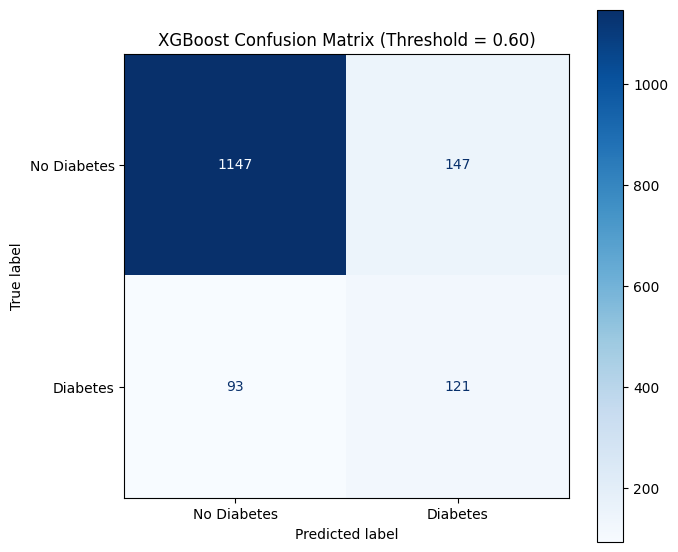

In [61]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_predictions,
    display_labels=["No Diabetes", "Diabetes"],
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title("XGBoost Confusion Matrix (Threshold = 0.60)")
plt.tight_layout()

plt.savefig(
    figures_dir / "xgboost_final_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

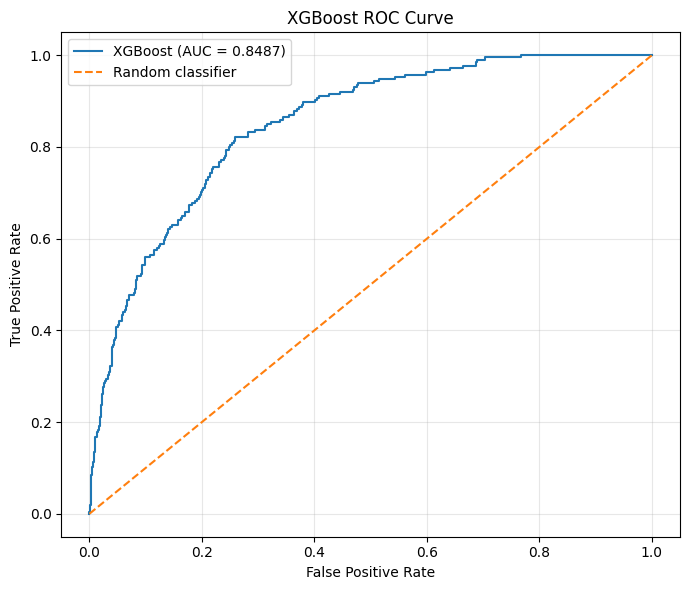

In [62]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, roc_thresholds = roc_curve(
    y_test,
    test_probabilities
)

roc_auc_value = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    fpr,
    tpr,
    label=f"XGBoost (AUC = {roc_auc_value:.4f})"
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("XGBoost ROC Curve")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    figures_dir / "xgboost_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

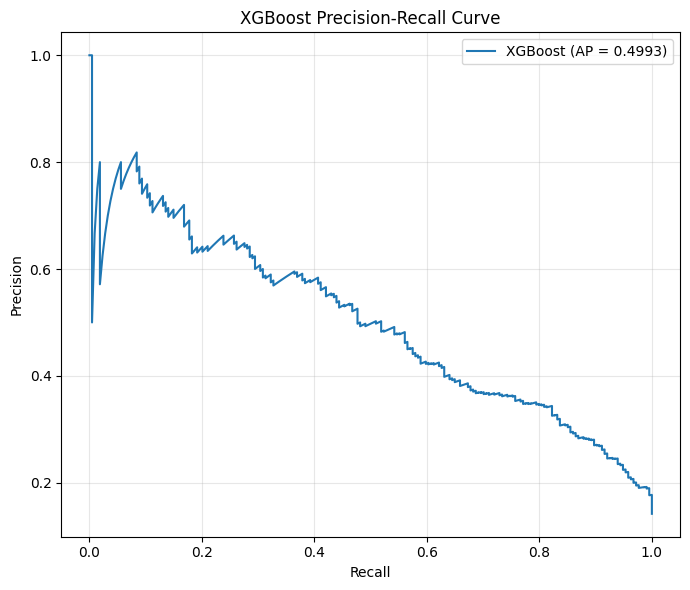

In [63]:
from sklearn.metrics import precision_recall_curve, average_precision_score

pr_precision, pr_recall, pr_thresholds = precision_recall_curve(
    y_test,
    test_probabilities
)

average_precision = average_precision_score(
    y_test,
    test_probabilities
)

fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    pr_recall,
    pr_precision,
    label=f"XGBoost (AP = {average_precision:.4f})"
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("XGBoost Precision-Recall Curve")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    figures_dir / "xgboost_precision_recall_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [64]:
final_test_metrics = pd.DataFrame([{
    "Model": "Tuned XGBoost",
    "Threshold": 0.60,
    "Accuracy": accuracy_score(y_test, final_predictions),
    "Precision": precision_score(y_test, final_predictions),
    "Recall": recall_score(y_test, final_predictions),
    "F1-score": f1_score(y_test, final_predictions),
    "ROC-AUC": roc_auc_score(y_test, test_probabilities),
    "Average Precision": average_precision_score(
        y_test, test_probabilities
    )
}])

display(final_test_metrics.round(4))

final_test_metrics.to_csv(
    tables_dir / "xgboost_final_test_metrics.csv",
    index=False
)

print("Final evaluation metrics saved.")

,Model,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,Tuned XGBoost,0.6,0.8408,0.4515,0.5654,0.5021,0.8487,0.4993


Final evaluation metrics saved.


## 11.14 XGBoost Feature Importance

This section examines the importance of the features used by the tuned XGBoost model. The analysis identifies the variables that contribute most to the model's predictive performance.

In [65]:
# Extract feature names after preprocessing
feature_names = best_xgb_pipeline[:-1].get_feature_names_out()

# Extract XGBoost feature importance
xgb_model = best_xgb_pipeline[-1]

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Display top 20 features
display(feature_importance.head(20).round(4))

# Save results
feature_importance.to_csv(
    tables_dir / "xgboost_feature_importance.csv",
    index=False
)

print("Feature importance results saved.")

,Feature,Importance
0,categorical__BPQ101D_1.0,0.1591
1,categorical__BPQ020_1.0,0.1028
2,categorical__PAD810U_b'W',0.0209
3,ordinal__DMDEDUC2,0.0180
4,ordinal__ALQ121,0.0173
5,categorical__RIDRETH1_3.0,0.0170
6,categorical__BPQ080_1.0,0.0162
7,categorical__PAD810U_b'',0.0155
8,numerical__RIDAGEYR,0.0154
9,numerical__BMXWAIST,0.0149


Feature importance results saved.


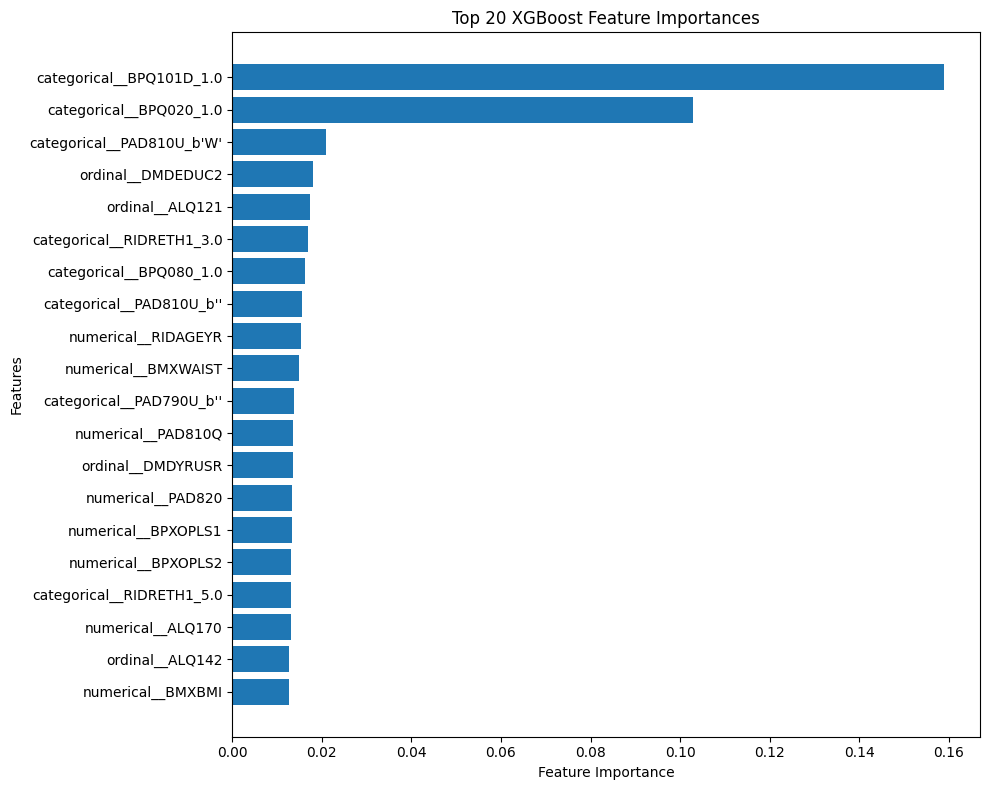

Feature importance plot saved.


In [66]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(20).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 20 XGBoost Feature Importances")
plt.tight_layout()

plt.savefig(
    figures_dir / "xgboost_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Feature importance plot saved.")

## 11.15 SHAP Model Explainability

SHAP (SHapley Additive exPlanations) is used to interpret the predictions of the tuned XGBoost model. It helps identify how individual features influence the model's predictions and provides both global and feature-level explanations.

### SHAP dependency\n\nIf SHAP is not installed in the active environment, install it once in Terminal with `python -m pip install shap`, restart the kernel, and continue.

In [67]:
import shap
import numpy as np
import pandas as pd

# Transform test data using the fitted preprocessing pipeline
X_test_transformed = best_xgb_pipeline[:-1].transform(X_test)

# Convert to DataFrame with feature names
feature_names = best_xgb_pipeline[:-1].get_feature_names_out()

X_test_transformed_df = pd.DataFrame(
    X_test_transformed,
    columns=feature_names,
    index=X_test.index
)

# Use a sample to keep SHAP computation manageable
X_shap = X_test_transformed_df.sample(
    n=min(300, len(X_test_transformed_df)),
    random_state=42
)

# Create SHAP explainer
xgb_model = best_xgb_pipeline[-1]
explainer = shap.TreeExplainer(xgb_model)

# Calculate SHAP values
shap_values = explainer.shap_values(X_shap)

print("SHAP values calculated successfully.")
print("SHAP sample shape:", np.array(shap_values).shape)

/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP values calculated successfully.
SHAP sample shape: (300, 87)


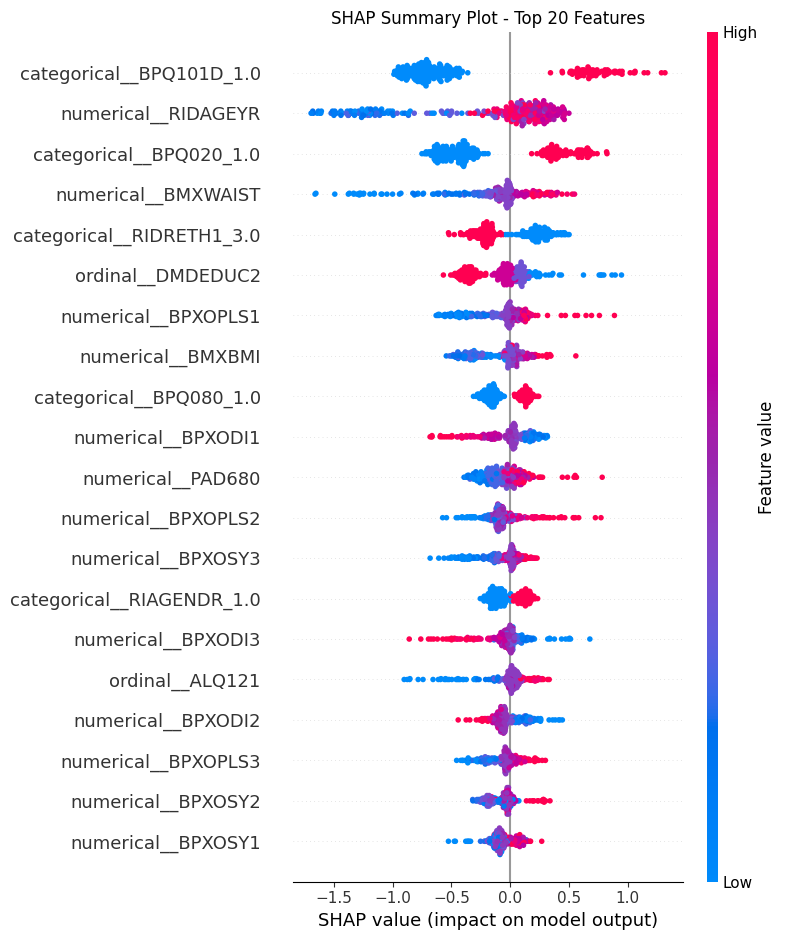

SHAP summary plot saved.


In [68]:
# Generate SHAP summary plot
plt.figure(figsize=(12, 8))

shap.summary_plot(
    shap_values,
    X_shap,
    max_display=20,
    show=False
)

plt.title("SHAP Summary Plot - Top 20 Features")
plt.tight_layout()

plt.savefig(
    figures_dir / "xgboost_shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("SHAP summary plot saved.")

In [69]:
# Calculate mean absolute SHAP values
shap_importance = pd.DataFrame({
    "Feature": X_shap.columns,
    "Mean_ABS_SHAP": np.abs(shap_values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    by="Mean_ABS_SHAP",
    ascending=False
).reset_index(drop=True)

display(shap_importance.head(20).round(4))

# Save SHAP importance table
shap_importance.to_csv(
    tables_dir / "xgboost_shap_feature_importance.csv",
    index=False
)

print("SHAP importance table saved.")

,Feature,Mean_ABS_SHAP
0,categorical__BPQ101D_1.0,0.7165
1,numerical__RIDAGEYR,0.4718
2,categorical__BPQ020_1.0,0.4706
3,numerical__BMXWAIST,0.2635
4,categorical__RIDRETH1_3.0,0.2380
5,ordinal__DMDEDUC2,0.1954
6,numerical__BPXOPLS1,0.1663
7,numerical__BMXBMI,0.1567
8,categorical__BPQ080_1.0,0.1533
9,numerical__BPXODI1,0.1452


SHAP importance table saved.


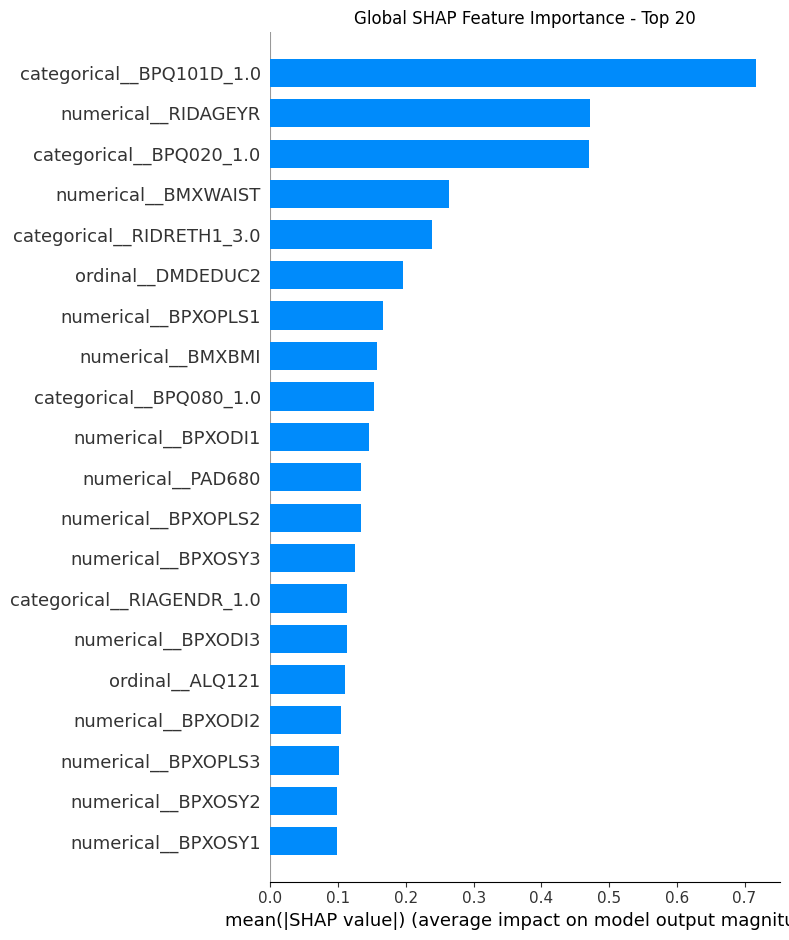

SHAP importance bar plot saved.


In [70]:
# SHAP global feature importance bar plot

plt.figure(figsize=(12, 8))

shap.summary_plot(
    shap_values,
    X_shap,
    plot_type="bar",
    max_display=20,
    show=False
)

plt.title("Global SHAP Feature Importance - Top 20")
plt.tight_layout()

plt.savefig(
    figures_dir / "xgboost_shap_importance_bar.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("SHAP importance bar plot saved.")

## 11.16 Model Interpretation and Limitations

The tuned XGBoost model was evaluated using an independent test dataset. At the selected classification threshold of 0.60, the model achieved an accuracy of 84.08%, precision of 45.15%, recall of 56.54%, F1-score of 50.21%, and ROC-AUC of 84.87%.

SHAP analysis was used to understand the contribution of individual predictors to model predictions. Age, blood pressure questionnaire variables, waist circumference, and BMI were among the most influential features.

### Model Limitations

1. The target variable represents self-reported diagnosed diabetes and may not identify individuals with undiagnosed diabetes.
2. NHANES is observational and cross-sectional; therefore, the model identifies predictive associations rather than causal relationships.
3. Missing values and questionnaire skip patterns may influence model performance.
4. The classification threshold affects the balance between precision and recall.
5. The model was evaluated on one held-out test split, so performance may vary across other populations or datasets.
6. The model is intended for research and educational purposes, not clinical diagnosis.

## 11.17 Final Model Summary and Results

The tuned XGBoost classifier was selected as the final model after comparing multiple machine learning algorithms and performing hyperparameter tuning.

The classification threshold was selected as 0.60 based on training-set out-of-fold predictions, optimizing the F1-score among the thresholds evaluated.

The final model was evaluated using the independent test dataset. Its performance is summarized below.

In [71]:
# Final model performance summary

final_model_summary = pd.DataFrame({
    "Evaluation Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC",
        "Average Precision"
    ],
    "Test Score": [
        accuracy_score(y_test, final_predictions),
        precision_score(y_test, final_predictions),
        recall_score(y_test, final_predictions),
        f1_score(y_test, final_predictions),
        roc_auc_score(y_test, test_probabilities),
        average_precision_score(y_test, test_probabilities)
    ]
})

display(final_model_summary.round(4))

# Save final model summary
final_model_summary.to_csv(
    tables_dir / "final_model_summary.csv",
    index=False
)

print("Final model summary saved.")

,Evaluation Metric,Test Score
0,Accuracy,0.8408
1,Precision,0.4515
2,Recall,0.5654
3,F1-Score,0.5021
4,ROC-AUC,0.8487
5,Average Precision,0.4993


Final model summary saved.


In [72]:
# Final confusion matrix values
tn, fp, fn, tp = confusion_matrix(
    y_test,
    final_predictions
).ravel()

confusion_summary = pd.DataFrame({
    "Prediction": ["No Diabetes", "Diabetes"],
    "Actual No Diabetes": [tn, fp],
    "Actual Diabetes": [fn, tp]
})

display(confusion_summary)

confusion_summary.to_csv(
    tables_dir / "final_confusion_matrix_summary.csv",
    index=False
)

print("Confusion matrix summary saved.")

,Prediction,Actual No Diabetes,Actual Diabetes
0,No Diabetes,1147,93
1,Diabetes,147,121


Confusion matrix summary saved.


## 11.18 Final Conclusion

This study developed and evaluated machine learning models to predict self-reported diagnosed diabetes using NHANES 2021–2023 data.

Multiple classification algorithms were compared, including Logistic Regression, Random Forest, Gradient Boosting, Support Vector Machine, Decision Tree, and XGBoost.

After hyperparameter tuning, XGBoost was selected as the final model. The classification threshold of 0.60 was selected using out-of-fold predictions from the training data.

On the independent test dataset, the final model achieved:
- Accuracy: 84.08%
- Precision: 45.15%
- Recall: 56.54%
- F1-score: 50.21%
- ROC-AUC: 84.87%
- Average Precision: 49.93%

SHAP analysis provided additional insight into the features influencing model predictions. Age, blood pressure questionnaire variables, waist circumference, and BMI were among the most influential features.

Overall, this project demonstrates how machine learning and explainability techniques can be applied to NHANES survey data to study patterns associated with self-reported diabetes. The results should be interpreted in the context of survey limitations, missing data, class imbalance, and the observational nature of the dataset. The model is intended for academic research and not for clinical diagnosis.

# 12. Final Project Validation

This section verifies the generated project outputs, including processed datasets, evaluation tables, and visualizations. The purpose is to ensure that the required results have been saved successfully and are available for the final project report.

In [73]:
from pathlib import Path

# Verify output directories
print("TABLES DIRECTORY:", tables_dir)
print("FIGURES DIRECTORY:", figures_dir)

# Check saved tables
print("\n========== SAVED TABLES ==========")

for file in sorted(tables_dir.glob("*")):
    if file.is_file():
        print("SAVED:", file.name)

# Check saved figures
print("\n========== SAVED FIGURES ==========")

for file in sorted(figures_dir.glob("*")):
    if file.is_file():
        print("SAVED:", file.name)

# Count files
table_count = sum(1 for f in tables_dir.glob("*") if f.is_file())
figure_count = sum(1 for f in figures_dir.glob("*") if f.is_file())

print("\n========== VALIDATION SUMMARY ==========")
print("Total tables:", table_count)
print("Total figures:", figure_count)

TABLES DIRECTORY: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables
FIGURES DIRECTORY: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/figures

========== SAVED TABLES ==========
SAVED: .gitkeep
SAVED: 01_missing_value_summary.csv
SAVED: 02_missingness_category_summary.csv
SAVED: 03_high_missingness_variables.csv
SAVED: 04_updated_missing_value_summary.csv
SAVED: 05_updated_missingness_category_summary.csv
SAVED: 06_numerical_feature_missingness.csv
SAVED: 07_categorical_feature_missingness.csv
SAVED: 08_missingness_correlation.csv
SAVED: 09_feature_retention_review.csv
SAVED: 10_high_missingness_feature_review.csv
SAVED: 11_high_missingness_retention_decisions.csv
SAVED: 12_questionnaire_skip_pattern_review.csv
SAVED: 13_nhanes_variable_documentation_review.csv
SAVED: 14_documentation_completeness_check.csv
SAVED: 15_final_missingness_documentation.csv
SAVED: 16_high_missingness_treatment_review.csv
SAVED: 17_missing_value_treatment_strategy.

# 13. Saving the Final Trained Model

The final tuned XGBoost pipeline is saved for future use. The saved pipeline includes the preprocessing steps and trained classifier, allowing predictions to be generated on new data using the same transformations.

In [74]:
import joblib

# Create model directory
model_dir = project_root / "models"
model_dir.mkdir(parents=True, exist_ok=True)

# Save the complete fitted pipeline
model_path = model_dir / "final_xgboost_diabetes_model.pkl"

joblib.dump(best_xgb_pipeline, model_path)

print("Final XGBoost model saved successfully.")
print("Model location:", model_path.resolve())

Final XGBoost model saved successfully.
Model location: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/models/final_xgboost_diabetes_model.pkl


In [75]:
# Load the saved model
loaded_model = joblib.load(model_path)

# Verify predictions on the test dataset
loaded_probabilities = loaded_model.predict_proba(X_test)[:, 1]

print("Model loaded successfully.")
print("Test predictions:", len(loaded_probabilities))
print("All probabilities finite:", np.isfinite(loaded_probabilities).all())

Model loaded successfully.
Test predictions: 1508
All probabilities finite: True


# 14. Model Deployment Readiness

This section demonstrates how the saved XGBoost pipeline can be used to generate diabetes predictions for new observations. The selected classification threshold of 0.60 is applied to convert predicted probabilities into binary classifications.

In [76]:
# Reusable prediction function

SELECTED_THRESHOLD = 0.60

def predict_diabetes(input_data, model=loaded_model):
    """
    Generate diabetes predictions using the trained XGBoost pipeline.

    input_data must contain the original model input features.
    """

    probabilities = model.predict_proba(input_data)[:, 1]

    predictions = (probabilities >= SELECTED_THRESHOLD).astype(int)

    results = pd.DataFrame({
        "Diabetes_Probability": probabilities,
        "Predicted_Class": predictions,
        "Predicted_Label": [
            "Diabetes" if value == 1 else "No Diabetes"
            for value in predictions
        ]
    })

    return results

In [77]:
# Test using the first 10 observations from X_test

sample_predictions = predict_diabetes(X_test.head(10))

display(sample_predictions.round(4))

print("Prediction function executed successfully.")

,Diabetes_Probability,Predicted_Class,Predicted_Label
0,0.8541,1,Diabetes
1,0.0094,0,No Diabetes
2,0.0460,0,No Diabetes
3,0.0546,0,No Diabetes
4,0.1887,0,No Diabetes
5,0.1514,0,No Diabetes
6,0.5250,0,No Diabetes
7,0.0044,0,No Diabetes
8,0.1313,0,No Diabetes
9,0.7781,1,Diabetes


Prediction function executed successfully.


# 15. Saving the Complete Model Configuration

The final model pipeline, selected classification threshold, and feature information are stored together as a reusable model artifact. This supports consistent predictions and future reproducibility.

In [78]:
# Save complete model configuration

final_model_bundle = {
    "model": loaded_model,
    "threshold": SELECTED_THRESHOLD,
    "feature_names": list(X_train.columns),
    "model_name": "Tuned XGBoost",
    "target": "DIABETES",
    "random_state": 42
}

final_bundle_path = model_dir / "final_xgboost_model_bundle.pkl"

joblib.dump(final_model_bundle, final_bundle_path)

print("Complete model bundle saved successfully.")
print("Location:", final_bundle_path.resolve())

Complete model bundle saved successfully.
Location: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/models/final_xgboost_model_bundle.pkl


In [79]:
# Reload and verify model bundle

verified_bundle = joblib.load(final_bundle_path)

print("Model:", verified_bundle["model_name"])
print("Threshold:", verified_bundle["threshold"])
print("Target:", verified_bundle["target"])
print("Number of input features:", len(verified_bundle["feature_names"]))
print("Model bundle verified successfully.")

Model: Tuned XGBoost
Threshold: 0.6
Target: DIABETES
Number of input features: 51
Model bundle verified successfully.


In [80]:
# Final project artifact validation

project_root = Path("..").resolve()

required_files = [
    project_root / "models/final_xgboost_diabetes_model.pkl",
    project_root / "models/final_xgboost_model_bundle.pkl",
    tables_dir / "final_model_summary.csv",
    tables_dir / "final_confusion_matrix_summary.csv",
    tables_dir / "xgboost_shap_feature_importance.csv",
    figures_dir / "xgboost_feature_importance.png",
    figures_dir / "xgboost_shap_summary.png",
    figures_dir / "xgboost_shap_importance_bar.png"
]

print("========== FINAL ARTIFACT CHECK ==========")

for file_path in required_files:
    status = "FOUND" if file_path.exists() else "MISSING"
    print(f"{status}: {file_path}")

missing_files = [f for f in required_files if not f.exists()]

print("\nTotal required files:", len(required_files))
print("Missing files:", len(missing_files))

if not missing_files:
    print("All required artifacts are available.")
else:
    print("Please check the missing files.")

========== FINAL ARTIFACT CHECK ==========
FOUND: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/models/final_xgboost_diabetes_model.pkl
FOUND: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/models/final_xgboost_model_bundle.pkl
FOUND: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/final_model_summary.csv
FOUND: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/final_confusion_matrix_summary.csv
FOUND: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/xgboost_shap_feature_importance.csv
FOUND: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/figures/xgboost_feature_importance.png
FOUND: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/figures/xgboost_shap_summary.png
FOUND: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/figures/xgboost_shap_importance_bar.png

Total required files: 8
Missing files: 0
All required artifacts are availa